# BAAI500: Approximate Similarity Search — Tasks 1 & 2

## Overview

**Task 1 — Similarity Search:** Compare Exact kNN, LSH, and HNSW across image and movie datasets.  
**Task 2 — OoD Detection:** Evaluate how search quality affects Out-of-Distribution detection.

### Datasets
| Dataset | Role | # Samples |
|---------|------|----------|
| InDSearch (ImageNet100) | Search database | ~95,000 |
| InDQuery (ImageNet100) | Image queries (InD test) | ~40,000 |
| Places365 | OoD queries | ~36,500 |
| MovieLens 10M | Movie similarity | 10,677 movies |

### Neural Network Configurations
| Config | Weights | Used For |
|--------|---------|----------|
| Conf1 | IMAGENET1K_V2 (standard pretrained) | Task 1 + NN-Guide (Task 2) |
| Conf2 | ConWideResNet50.pt (contrastive) | Task 1 + Deep Nearest Neighbors (Task 2) |

Both extract **2048-dim features from the penultimate layer**.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Adjust path so we can import from src/
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import faiss
import time
import json

from feature_extraction import (
    WideResNetFeatureExtractor, save_features, load_features, normalize_l2, softmax
)
from movielens_preprocessing import (
    MovieLensPreprocessor, search_movielens_knn
)
from similarity_search import (
    build_exact_index, build_lsh_index, build_hnsw_index, search,
    amortized_time, run_single_config, HYPERPARAM_RANGES, K_VALUES
)
from evaluation import compute_recall_at_k, save_results, print_results_table
from ood_detection import (
    deep_nearest_neighbors_score, nn_guide_score,
    random_knn_indices, compute_auroc, compute_fpr_at_tpr95,
    collect_neighbor_logits, maximum_softmax_probability, negative_energy
)

# ── Paths ──────────────────────────────────────────────────────────────────────
DATA_DIR      = project_root / 'data'
RAW_DIR       = DATA_DIR / 'raw'
PROCESSED_DIR = DATA_DIR / 'processed'
RESULTS_DIR   = DATA_DIR / 'results'

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ── Plot style ─────────────────────────────────────────────────────────────────
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('colorblind')
np.random.seed(42)

print(f"Project root : {project_root}")
print(f"FAISS version: {faiss.__version__}")

Project root : c:\Users\Emil\Desktop\Emil Bachelor projekt
FAISS version: 1.13.2


---
# TASK 1 — Similarity Search
---
## 1.1 Feature Extraction

Extract features from:
- `InDSearch/`  → search database (~95,000 images)
- `InDQuery/`   → query set — same distribution as database (~40,000 images)
- `Places365/`  → query set — different distribution / OoD (~36,500 images)

Run **once** and save to `data/processed/`. Skip if already extracted.

In [2]:
# Paths to image collections (adjust if your folder names differ)
IND_SEARCH_DIR = RAW_DIR / 'InDSearch'
IND_QUERY_DIR  = RAW_DIR / 'InDQuery'
PLACES_DIR     = RAW_DIR / 'Places365'

# Conf2 weights are in the NeuralNetworks folder at the project root
CONF2_WEIGHTS  = project_root / 'NeuralNetworks' / 'wrn50_supcon.pth'

SPLITS = {
    'InDSearch': IND_SEARCH_DIR,
    'InDQuery':  IND_QUERY_DIR,
    'Places365': PLACES_DIR,
}

def extract_and_save(config: str, conf2_weights=None, batch_size=32):
    """Extract features for all three splits and save to disk."""
    extractor = WideResNetFeatureExtractor(
        config=config,
        conf2_weights_path=conf2_weights if config == 'conf2' else None
    )
    for split_name, split_dir in SPLITS.items():
        out_file = PROCESSED_DIR / f"{split_name}_{config}_features.npy"
        if out_file.exists():
            print(f"  Already extracted: {out_file.name} - skipping")
            continue
        print(f"Extracting {split_name} ({config})...")
        features, logits, image_ids = extractor.extract_from_directory(
            split_dir, batch_size=batch_size, recursive=True
        )
        save_features(features, logits, image_ids, PROCESSED_DIR, split_name, config)

# Run extraction
print('=== Conf1 (IMAGENET1K_V2) ===')
extract_and_save('conf1', batch_size=32)

print('=== Conf2 (wrn50_supcon.pth) ===')
if CONF2_WEIGHTS.exists():
    extract_and_save('conf2', conf2_weights=CONF2_WEIGHTS, batch_size=32)
else:
    print(f"WARNING: {CONF2_WEIGHTS} not found.")
    print("Expected: NeuralNetworks/wrn50_supcon.pth in the project root.")


=== Conf1 (IMAGENET1K_V2) ===
Conf1: Loaded IMAGENET1K_V2 pretrained weights
Device: cpu
Feature dimension: 2048 (penultimate layer)
  Already extracted: InDSearch_conf1_features.npy - skipping
  Already extracted: InDQuery_conf1_features.npy - skipping
  Already extracted: Places365_conf1_features.npy - skipping
=== Conf2 (wrn50_supcon.pth) ===
Conf2: Loaded contrastive weights from c:\Users\Emil\Desktop\Emil Bachelor projekt\NeuralNetworks\wrn50_supcon.pth
       Classes: 100
Device: cpu
Feature dimension: 2048 (penultimate layer)
  Already extracted: InDSearch_conf2_features.npy - skipping
  Already extracted: InDQuery_conf2_features.npy - skipping
  Already extracted: Places365_conf2_features.npy - skipping


In [3]:
# Load extracted features into memory
print("Loading features...")
data = {}
for config in ['conf1', 'conf2']:
    data[config] = {}
    for split in ['InDSearch', 'InDQuery', 'Places365']:
        feat_path = PROCESSED_DIR / f"{split}_{config}_features.npy"
        logit_path = PROCESSED_DIR / f"{split}_{config}_logits.npy"
        if feat_path.exists():
            data[config][split] = {
                'features': np.load(feat_path),
                'logits':   np.load(logit_path) if logit_path.exists() else None
            }
            print(f"  {config}/{split}: {data[config][split]['features'].shape}")
        else:
            print(f"  MISSING: {feat_path}")

print("\nNOTE: All vectors will be L2-normalized before OoD tasks (Task 2).")
print("For Task 1 similarity search, normalization is applied per-metric inside the search functions.")

Loading features...
  conf1/InDSearch: (190000, 2048)
  conf1/InDQuery: (80000, 2048)
  conf1/Places365: (73000, 2048)
  conf2/InDSearch: (190000, 2048)
  conf2/InDQuery: (80000, 2048)
  conf2/Places365: (73000, 2048)

NOTE: All vectors will be L2-normalized before OoD tasks (Task 2).
For Task 1 similarity search, normalization is applied per-metric inside the search functions.


## 1.2 MovieLens Preprocessing

- Primary: ml-10m (~10M ratings, 10,677 movies, 69,878 users)
- Backup:  ml-1m  (only if RAM > 16 GB is exceeded)
- Each MOVIE = 69,878-dimensional sparse vector over users

In [4]:
ML_VERSION = '10m'  # change to '1m' only if memory overflows

ml_proc = MovieLensPreprocessor(RAW_DIR, version=ML_VERSION)

ml_matrix_path = PROCESSED_DIR / f"ml{ML_VERSION}_movie_matrix.npy"

if ml_matrix_path.exists():
    print("Loading pre-processed MovieLens matrix...")
    ml_proc.load_processed(PROCESSED_DIR)
else:
    print("Downloading and preprocessing MovieLens...")
    ml_proc.download()
    ml_proc.load_ratings()
    ml_proc.create_movie_vectors(binary=False, normalize=True)
    ml_proc.save_processed(PROCESSED_DIR)

ml_matrix = ml_proc.movie_matrix  # shape: (n_movies, n_users)
print(f"\nMovieLens matrix: {ml_matrix.shape}")
print(f"  n_movies: {ml_matrix.shape[0]}")
print(f"  n_users (dim): {ml_matrix.shape[1]}")

MovieLens 10m: 10M ratings, 10677 movies, 69878 users
Loading pre-processed MovieLens matrix...
Loaded movie matrix: (10677, 69878)

MovieLens matrix: (10677, 69878)
  n_movies: 10677
  n_users (dim): 69878


## 1.3 Similarity Search — Images

### Setup
- **Database**: InDSearch features
- **Queries**: InDQuery features  AND  Places365 features (separately)
- **Metrics**: Euclidean + Cosine  (LSH: cosine only)
- **k ∈ {1, 5, 10, 30}**

In [5]:
def run_image_experiment(config: str, metric: str):
    """
    Run complete image similarity search experiment for one (config, metric) pair.
    Returns a list of result dicts (one per algorithm × k combination).
    """
    db   = data[config]['InDSearch']['features']
    q_id = data[config]['InDQuery']['features']
    q_oo = data[config]['Places365']['features']

    results = []

    # ── 1. Exact kNN (ground truth) ──────────────────────────────────────────
    print(f"  [Exact] building index ({metric})...")
    exact_idx, exact_bt = build_exact_index(db, metric)

    for query_name, queries in [('InDQuery', q_id), ('Places365', q_oo)]:
        exact_res = search(exact_idx, queries, max(K_VALUES), metric, exact_bt)
        results.append({
            'config': config, 'algorithm': 'exact', 'metric': metric,
            'query_set': query_name, 'hyperparams': {},
            'index_build_time': exact_bt,
            'indices_maxk': exact_res.indices,
            'avg_query_time': exact_res.avg_query_time,
            'query_time_total': exact_res.query_time_total,
        })

    # Store ground truth for recall computation
    gt_id = search(exact_idx, q_id, max(K_VALUES), metric, exact_bt).indices
    gt_oo = search(exact_idx, q_oo, max(K_VALUES), metric, exact_bt).indices

    # ── 2. LSH (cosine only) ─────────────────────────────────────────────────
    if metric == 'cosine':
        for nbits in HYPERPARAM_RANGES['images']['lsh']['nbits']:
            print(f"  [LSH] nbits={nbits}...")
            idx, bt = build_lsh_index(db, nbits)
            for query_name, queries in [('InDQuery', q_id), ('Places365', q_oo)]:
                res = search(idx, queries, max(K_VALUES), 'cosine', bt)
                results.append({
                    'config': config, 'algorithm': 'lsh', 'metric': 'cosine',
                    'query_set': query_name, 'hyperparams': {'nbits': nbits},
                    'index_build_time': bt,
                    'indices_maxk': res.indices,
                    'avg_query_time': res.avg_query_time,
                    'query_time_total': res.query_time_total,
                })

    # ── 3. HNSW ──────────────────────────────────────────────────────────────
    hp = HYPERPARAM_RANGES['images']['hnsw']
    for M in hp['M']:
        for ef_c in hp['ef_construction']:
            print(f"  [HNSW] M={M}, efC={ef_c} ({metric})...")
            # Build once per (M, efC) combination
            idx, bt = build_hnsw_index(db, metric, M, ef_c, ef_search=hp['ef_search'][0])
            for ef_s in hp['ef_search']:
                idx.hnsw.efSearch = ef_s
                for query_name, queries in [('InDQuery', q_id), ('Places365', q_oo)]:
                    res = search(idx, queries, max(K_VALUES), metric, bt)
                    results.append({
                        'config': config, 'algorithm': 'hnsw', 'metric': metric,
                        'query_set': query_name,
                        'hyperparams': {'M': M, 'ef_construction': ef_c, 'ef_search': ef_s},
                        'index_build_time': bt,
                        'indices_maxk': res.indices,
                        'avg_query_time': res.avg_query_time,
                        'query_time_total': res.query_time_total,
                    })

    # ── Compute recall@k for all results ─────────────────────────────────────
    rows = []
    for r in results:
        gt = gt_id if r['query_set'] == 'InDQuery' else gt_oo
        n_q = r['indices_maxk'].shape[0]
        for k in K_VALUES:
            recall = compute_recall_at_k(r['indices_maxk'][:, :k], gt[:, :k])
            rows.append({
                'config':           r['config'],
                'algorithm':        r['algorithm'],
                'metric':           r['metric'],
                'query_set':        r['query_set'],
                'k':                k,
                'hyperparams':      str(r['hyperparams']),
                'index_build_time': r['index_build_time'],
                'avg_query_time':   r['avg_query_time'],
                'amortized_time':   amortized_time(r['index_build_time'], r['query_time_total'], n_q),
                'recall':           recall,
            })

    return pd.DataFrame(rows)

print("Image experiment function defined.")
print("Run the next cell to start experiments (may take a while for large datasets).")

Image experiment function defined.
Run the next cell to start experiments (may take a while for large datasets).


In [6]:
# Run experiments — Conf1
image_dfs = []
for config in ['conf1', 'conf2']:
    if config not in data or 'InDSearch' not in data.get(config, {}):
        print(f"Skipping {config} — features not extracted yet")
        continue
    for metric in ['euclidean', 'cosine']:
        print(f"\n{'='*60}")
        print(f"Config={config}  Metric={metric}")
        print(f"{'='*60}")
        df = run_image_experiment(config, metric)
        image_dfs.append(df)

if image_dfs:
    image_results = pd.concat(image_dfs, ignore_index=True)
    image_results.to_csv(RESULTS_DIR / 'image_search_results.csv', index=False)
    print(f"\nSaved {len(image_results)} result rows to data/results/image_search_results.csv")
else:
    print("No image results yet — extract features first.")


Config=conf1  Metric=euclidean
  [Exact] building index (euclidean)...


KeyboardInterrupt: 

## 1.4 Image Results — Visualization

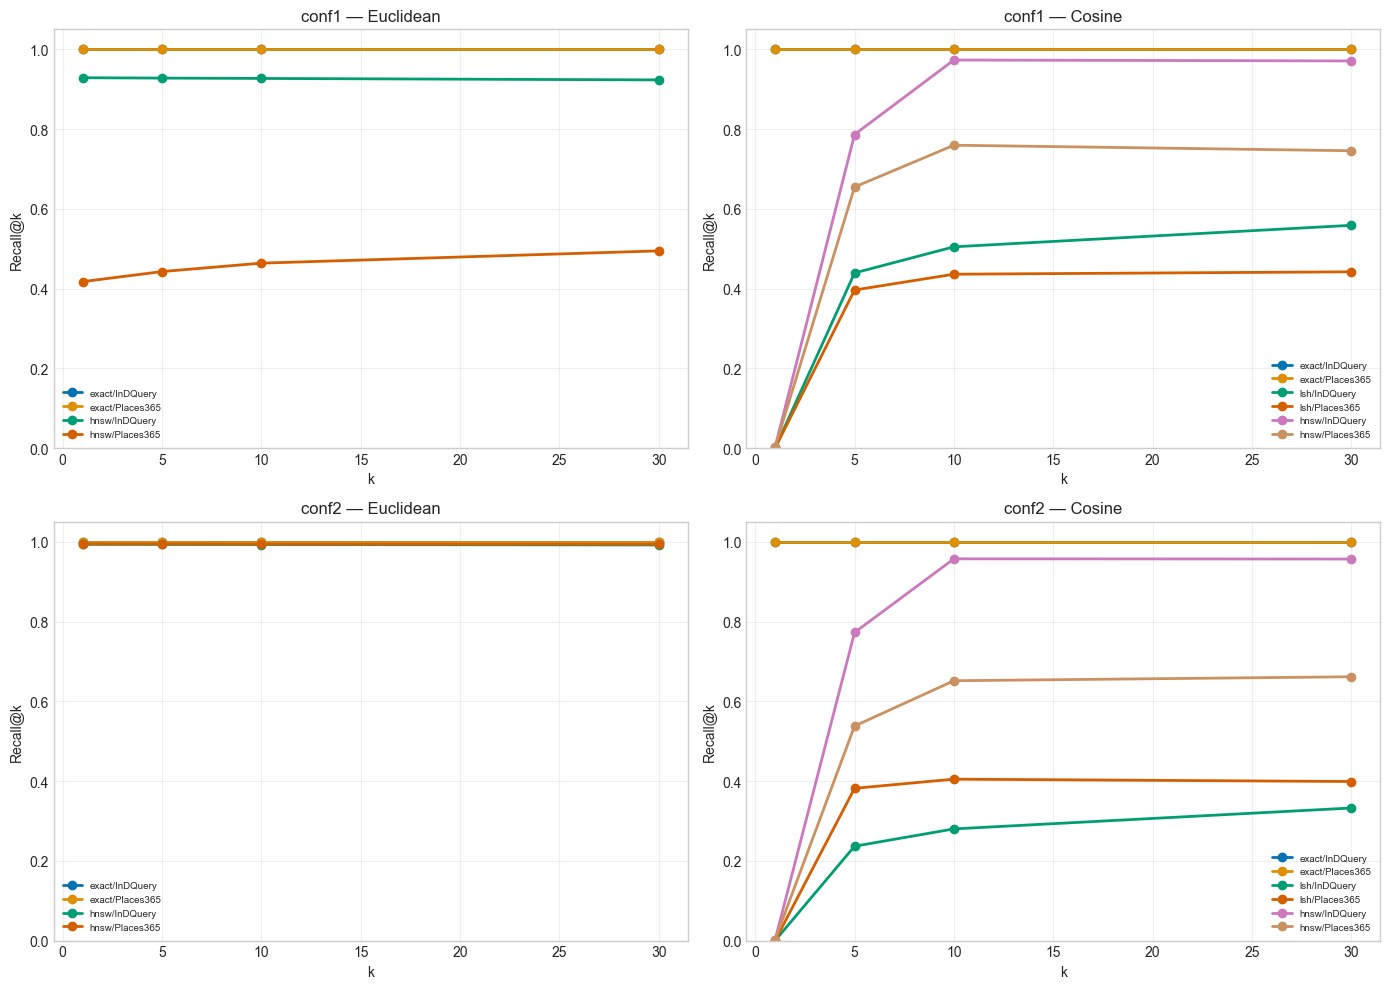

In [7]:
# Load results if already saved
result_path = RESULTS_DIR / 'image_search_results.csv'
if result_path.exists():
    image_results = pd.read_csv(result_path)

# ── Plot 1: Recall@k for each config × metric × query_set ────────────────────
configs   = ['conf1', 'conf2']
metrics   = ['euclidean', 'cosine']
q_sets    = ['InDQuery', 'Places365']
algos     = ['exact', 'lsh', 'hnsw']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for i, (config, metric) in enumerate([(c, m) for c in configs for m in metrics]):
    ax = axes[i // 2, i % 2]
    for algo in algos:
        if algo == 'lsh' and metric == 'euclidean':
            continue
        for qs in q_sets:
            sub = image_results[
                (image_results['config'] == config) &
                (image_results['algorithm'] == algo) &
                (image_results['metric'] == metric) &
                (image_results['query_set'] == qs)
            ].groupby('k')['recall'].mean().reset_index()
            ax.plot(sub['k'], sub['recall'],
                    marker='o', label=f'{algo}/{qs}', linewidth=2)
    ax.set_title(f'{config} — {metric.capitalize()}')
    ax.set_xlabel('k'); ax.set_ylabel('Recall@k')
    ax.set_ylim(0, 1.05); ax.legend(fontsize=7); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'image_recall_vs_k.png', dpi=150)
plt.show()

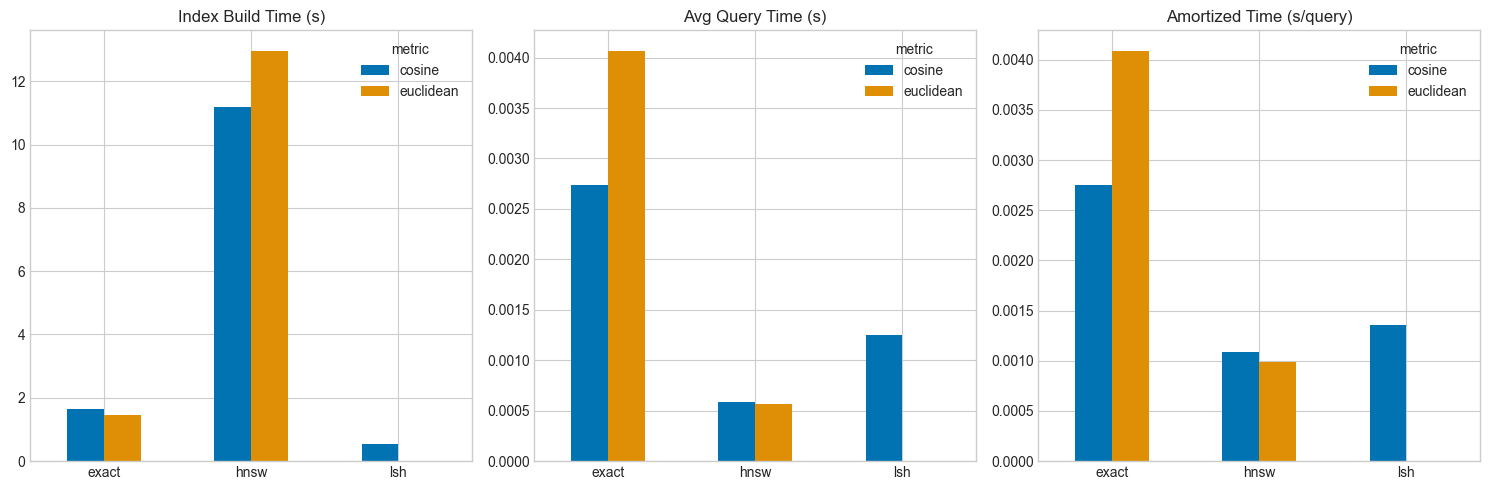

In [8]:
# ── Plot 2: Timing comparison (build, query, amortized) ──────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
timing_df = image_results.groupby(['algorithm', 'metric']).agg(
    index_build_time=('index_build_time', 'first'),
    avg_query_time=('avg_query_time', 'mean'),
    amortized_time=('amortized_time', 'mean')
).reset_index()

for ax, col, title in zip(
    axes,
    ['index_build_time', 'avg_query_time', 'amortized_time'],
    ['Index Build Time (s)', 'Avg Query Time (s)', 'Amortized Time (s/query)']
):
    pivot = timing_df.pivot(index='algorithm', columns='metric', values=col)
    pivot.plot(kind='bar', ax=ax, rot=0)
    ax.set_title(title); ax.set_xlabel('')

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'image_timing.png', dpi=150)
plt.show()

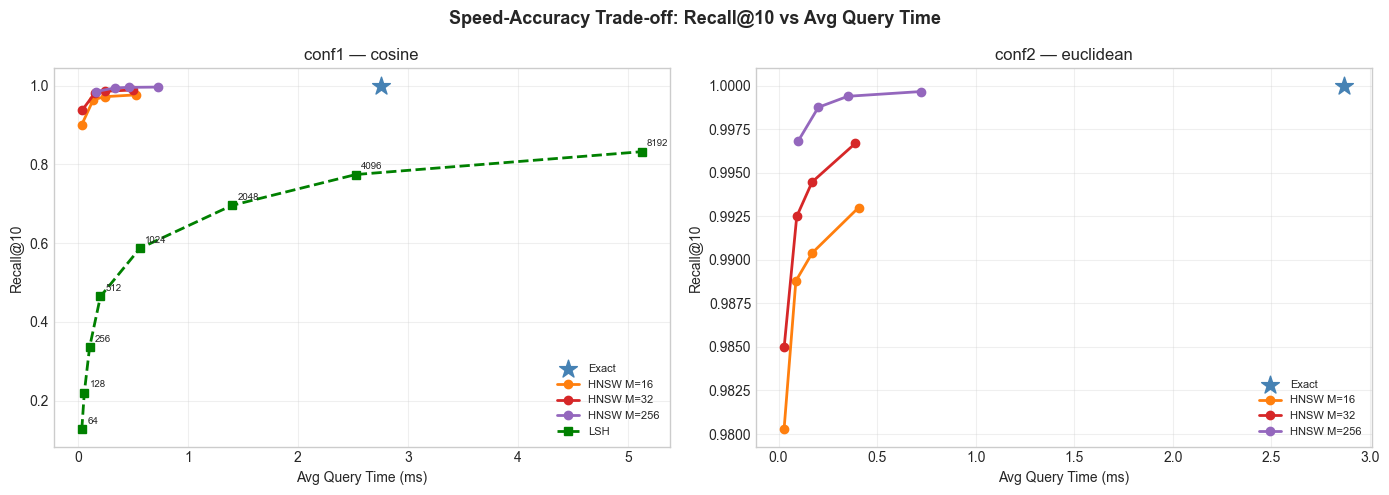

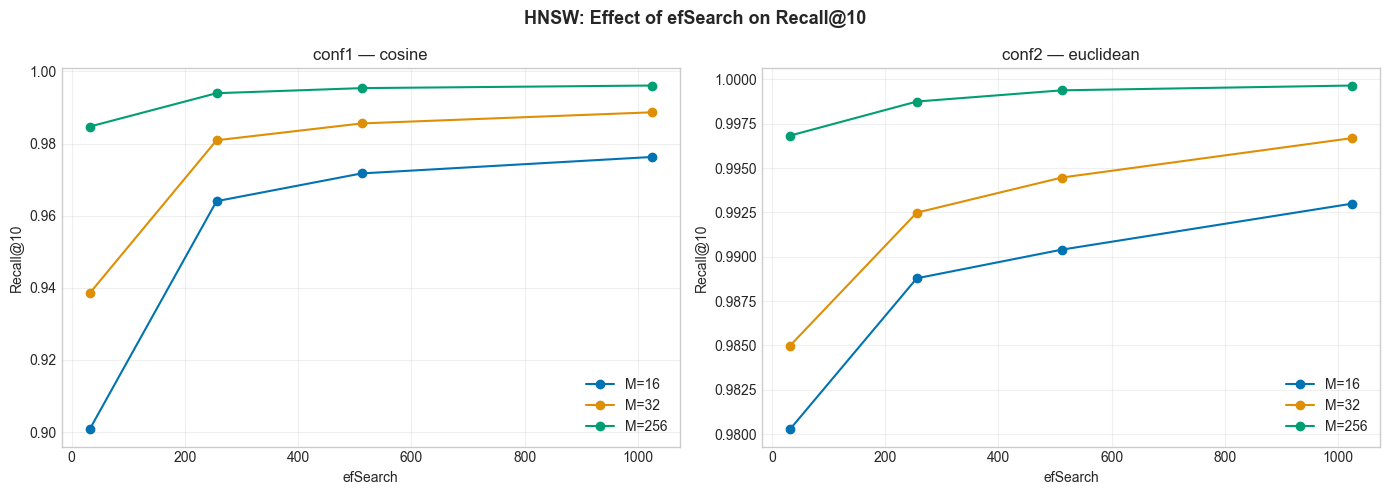

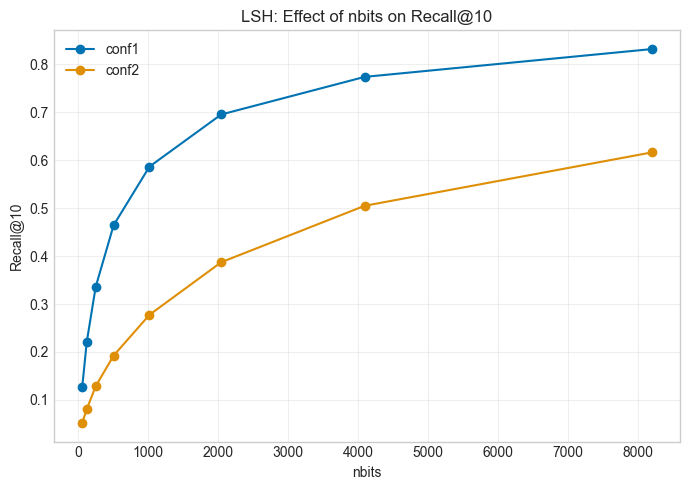

Saved: recall_vs_querytime.png, hnsw_efsearch_recall.png, lsh_nbits_recall.png


In [9]:
# ── Plot 3: Recall@10 vs Query Time — Curves (Speed-Accuracy Trade-off) ──────
import ast

img_res = pd.read_csv(RESULTS_DIR / 'image_search_results.csv')
img_res['hp'] = img_res['hyperparams'].apply(lambda x: ast.literal_eval(x) if x != '{}' else {})
img_res['ef_search'] = img_res['hp'].apply(lambda x: x.get('ef_search', None))
img_res['nbits']     = img_res['hp'].apply(lambda x: x.get('nbits', None))
img_res['M']         = img_res['hp'].apply(lambda x: x.get('M', None))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Speed-Accuracy Trade-off: Recall@10 vs Avg Query Time', fontsize=13, fontweight='bold')

for ax, (config, metric) in zip(axes, [('conf1', 'cosine'), ('conf2', 'euclidean')]):
    sub = img_res[(img_res['config'] == config) &
                  (img_res['metric'] == metric) &
                  (img_res['query_set'] == 'InDQuery') &
                  (img_res['k'] == 10)]

    # Exact — single star marker
    exact = sub[sub['algorithm'] == 'exact']
    if len(exact) > 0:
        ax.scatter(exact['avg_query_time'].mean() * 1000, exact['recall'].mean(),
                   color='steelblue', s=180, zorder=5, label='Exact', marker='*')

    # HNSW — one curve per M value (average over efC, sort by efSearch)
    hnsw = sub[sub['algorithm'] == 'hnsw'].copy()
    colors_hnsw = ['#ff7f0e', '#d62728', '#9467bd']
    for idx, M_val in enumerate(sorted(hnsw['M'].dropna().unique())):
        m_sub = (hnsw[hnsw['M'] == M_val]
                 .groupby('ef_search')
                 .agg(recall=('recall','mean'), time=('avg_query_time','mean'))
                 .reset_index()
                 .sort_values('ef_search'))
        ax.plot(m_sub['time'] * 1000, m_sub['recall'], marker='o',
                color=colors_hnsw[idx % len(colors_hnsw)],
                label=f'HNSW M={int(M_val)}', linewidth=2)

    # LSH — single curve sorted by nbits, annotated
    lsh = sub[sub['algorithm'] == 'lsh'].copy()
    if len(lsh) > 0:
        lsh_curve = (lsh.groupby('nbits')
                     .agg(recall=('recall','mean'), time=('avg_query_time','mean'))
                     .reset_index()
                     .sort_values('nbits'))
        ax.plot(lsh_curve['time'] * 1000, lsh_curve['recall'], marker='s',
                color='green', label='LSH', linestyle='--', linewidth=2)
        for _, row in lsh_curve.iterrows():
            ax.annotate(str(int(row['nbits'])), (row['time']*1000, row['recall']),
                        textcoords='offset points', xytext=(4, 4), fontsize=7)

    ax.set_xlabel('Avg Query Time (ms)')
    ax.set_ylabel('Recall@10')
    ax.set_title(f'{config} — {metric}')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'recall_vs_querytime.png', dpi=150)
plt.show()

# ── Plot 4: HNSW — Effect of efSearch on Recall@10 ──────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('HNSW: Effect of efSearch on Recall@10', fontsize=13, fontweight='bold')

for ax, (config, metric) in zip(axes, [('conf1', 'cosine'), ('conf2', 'euclidean')]):
    sub = img_res[(img_res['config'] == config) &
                  (img_res['metric'] == metric) &
                  (img_res['algorithm'] == 'hnsw') &
                  (img_res['query_set'] == 'InDQuery') &
                  (img_res['k'] == 10)]
    if len(sub) == 0:
        ax.set_title(f'{config} — {metric} (no data)'); continue
    for M_val in sorted(sub['M'].dropna().unique()):
        m_sub = sub[sub['M'] == M_val].groupby('ef_search')['recall'].mean().reset_index()
        ax.plot(m_sub['ef_search'], m_sub['recall'], marker='o', label=f'M={int(M_val)}')
    ax.set_xlabel('efSearch'); ax.set_ylabel('Recall@10')
    ax.set_title(f'{config} — {metric}')
    ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'hnsw_efsearch_recall.png', dpi=150)
plt.show()

# ── Plot 5: LSH — Effect of nbits on Recall@10 ──────────────────────────────
fig, axes = plt.subplots(1, 1, figsize=(7, 5))
sub = img_res[(img_res['algorithm'] == 'lsh') &
              (img_res['query_set'] == 'InDQuery') &
              (img_res['k'] == 10)]
for config in ['conf1', 'conf2']:
    cs = sub[sub['config'] == config].groupby('nbits')['recall'].mean().reset_index()
    axes.plot(cs['nbits'], cs['recall'], marker='o', label=config)
axes.set_xlabel('nbits'); axes.set_ylabel('Recall@10')
axes.set_title('LSH: Effect of nbits on Recall@10')
axes.legend(); axes.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'lsh_nbits_recall.png', dpi=150)
plt.show()
print('Saved: recall_vs_querytime.png, hnsw_efsearch_recall.png, lsh_nbits_recall.png')


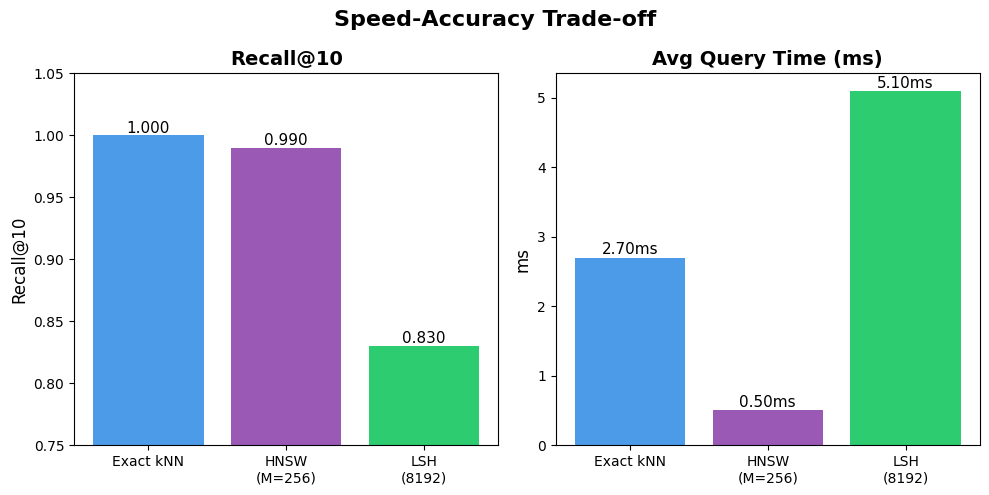

In [3]:
import matplotlib.pyplot as plt
import numpy as np

methods = ['Exact kNN', 'HNSW\n(M=256)', 'LSH\n(8192)']
recall  = [1.000, 0.990, 0.830]
times   = [2.70,  0.50,  5.10]
colors  = ['#4C9BE8', '#9B59B6', '#2ECC71']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Recall
ax1.bar(methods, recall, color=colors)
ax1.set_title('Recall@10', fontsize=14, fontweight='bold')
ax1.set_ylim(0.75, 1.05)
ax1.set_ylabel('Recall@10', fontsize=12)
for i, v in enumerate(recall):
    ax1.text(i, v + 0.002, f'{v:.3f}', ha='center', fontsize=11)

# Query time
ax2.bar(methods, times, color=colors)
ax2.set_title('Avg Query Time (ms)', fontsize=14, fontweight='bold')
ax2.set_ylabel('ms', fontsize=12)
for i, v in enumerate(times):
    ax2.text(i, v + 0.05, f'{v:.2f}ms', ha='center', fontsize=11)

fig.suptitle('Speed-Accuracy Trade-off', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('speed_accuracy_bars.png', dpi=150, bbox_inches='tight')
plt.show()


## 1.5 Similarity Search — MovieLens

- Entire movie matrix is both the database and the query pool
- Search k+1 neighbors, then remove the query movie itself
- Only cosine distance
- Vary number of queries: 100 → 500 → 1000 → 2000

In [ ]:
def run_movielens_experiment(n_queries_list, metric='cosine'):
    """
    Run MovieLens similarity search experiment.
    Note: metric is always 'cosine' per project spec.
    """
    assert metric == 'cosine', "MovieLens only uses cosine distance"
    db = ml_matrix  # (n_movies, n_users)
    rows = []

    for n_q in n_queries_list:
        query_indices = ml_proc.select_query_movies(n_queries=n_q)
        queries = db[query_indices]

        # ── Exact ────────────────────────────────────────────────────────────
        print(f"  [Exact] n_queries={n_q}...")
        exact_idx, exact_bt = build_exact_index(db, 'cosine')
        # Search k+1 to remove self; use max_k+1
        exact_res = search(exact_idx, queries, max(K_VALUES) + 1, 'cosine', exact_bt)
        # Ground truth (self removed inside search_movielens_knn)
        gt_indices, _ = search_movielens_knn(db, query_indices, exact_idx, max(K_VALUES))

        for k in K_VALUES:
            rows.append({
                'algorithm': 'exact', 'metric': 'cosine', 'k': k,
                'n_queries': n_q, 'hyperparams': {},
                'index_build_time': exact_bt,
                'avg_query_time': exact_res.avg_query_time,
                'amortized_time': amortized_time(exact_bt, exact_res.query_time_total, n_q),
                'recall': 1.0  # exact is ground truth
            })

        # ── LSH ──────────────────────────────────────────────────────────────
        for nbits in HYPERPARAM_RANGES['movies']['lsh']['nbits']:
            print(f"  [LSH] nbits={nbits}, n_queries={n_q}...")
            idx, bt = build_lsh_index(db, nbits)
            res = search(idx, queries, max(K_VALUES) + 1, 'cosine', bt)
            approx_indices, _ = search_movielens_knn(db, query_indices, idx, max(K_VALUES))
            for k in K_VALUES:
                recall = compute_recall_at_k(approx_indices[:, :k], gt_indices[:, :k])
                rows.append({
                    'algorithm': 'lsh', 'metric': 'cosine', 'k': k,
                    'n_queries': n_q, 'hyperparams': {'nbits': nbits},
                    'index_build_time': bt,
                    'avg_query_time': res.avg_query_time,
                    'amortized_time': amortized_time(bt, res.query_time_total, n_q),
                    'recall': recall
                })

        # ── HNSW ─────────────────────────────────────────────────────────────
        hp = HYPERPARAM_RANGES['movies']['hnsw']
        for M in hp['M']:
            for ef_c in hp['ef_construction']:
                print(f"  [HNSW] M={M}, efC={ef_c}, n_queries={n_q}...")
                idx, bt = build_hnsw_index(db, 'cosine', M, ef_c, hp['ef_search'][0])
                for ef_s in hp['ef_search']:
                    idx.hnsw.efSearch = ef_s
                    res = search(idx, queries, max(K_VALUES) + 1, 'cosine', bt)
                    approx_indices, _ = search_movielens_knn(db, query_indices, idx, max(K_VALUES))
                    for k in K_VALUES:
                        recall = compute_recall_at_k(approx_indices[:, :k], gt_indices[:, :k])
                        rows.append({
                            'algorithm': 'hnsw', 'metric': 'cosine', 'k': k,
                            'n_queries': n_q,
                            'hyperparams': {'M': M, 'ef_construction': ef_c, 'ef_search': ef_s},
                            'index_build_time': bt,
                            'avg_query_time': res.avg_query_time,
                            'amortized_time': amortized_time(bt, res.query_time_total, n_q),
                            'recall': recall
                        })
    return pd.DataFrame(rows)

# Start with small n_queries, then scale up
N_QUERIES_LIST = [500, 1000, 2000, 5000, 10000]
print(f"Running MovieLens experiments for n_queries in {N_QUERIES_LIST}")
ml_results = run_movielens_experiment(N_QUERIES_LIST)
ml_results.to_csv(RESULTS_DIR / 'movielens_search_results.csv', index=False)
print(f"Saved {len(ml_results)} result rows")

In [ ]:
# ── MovieLens Visualizations (load from CSV for robustness) ─────────────────
import ast, pandas as pd

ml_results = pd.read_csv(RESULTS_DIR / 'movielens_search_results.csv')
ml_results['hp'] = ml_results['hyperparams'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) and x != '{}' else {})
ml_results['ef_search'] = ml_results['hp'].apply(lambda x: x.get('ef_search', None))
ml_results['nbits_val'] = ml_results['hp'].apply(lambda x: x.get('nbits', None))
ml_results['M_val']     = ml_results['hp'].apply(lambda x: x.get('M', None))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('MovieLens — Similarity Search Results', fontsize=13, fontweight='bold')

# Left: Recall@k
ax = axes[0]
for algo in ['lsh', 'hnsw']:
    sub = ml_results[(ml_results['algorithm'] == algo) & (ml_results['n_queries'] == 1000)]
    mean_rec = sub.groupby('k')['recall'].mean()
    ax.plot(mean_rec.index, mean_rec.values, marker='o', label=algo, linewidth=2)
ax.set_xlabel('k'); ax.set_ylabel('Recall@k')
ax.set_title('Recall@k (Cosine, n_queries=1000)')
ax.set_ylim(0, 1.05); ax.legend(); ax.grid(True, alpha=0.3)

# Middle: Amortized time vs n_queries
ax = axes[1]
for algo in ['exact', 'lsh', 'hnsw']:
    sub = ml_results[(ml_results['algorithm'] == algo) & (ml_results['k'] == 10)]
    mean_am = sub.groupby('n_queries')['amortized_time'].mean()
    ax.plot(mean_am.index, mean_am.values, marker='o', label=algo, linewidth=2)
ax.set_xlabel('Number of Queries'); ax.set_ylabel('Amortized Time (s/query)')
ax.set_title('Amortized Time vs Query Count')
ax.legend(); ax.grid(True, alpha=0.3)

# Right: HNSW efSearch vs Recall@10 — one curve per M value
ax = axes[2]
hnsw_sub = ml_results[(ml_results['algorithm'] == 'hnsw') & (ml_results['k'] == 10)].copy()
for M_val in sorted(hnsw_sub['M_val'].dropna().unique()):
    m_sub = (hnsw_sub[hnsw_sub['M_val'] == M_val]
             .groupby('ef_search')['recall'].mean().reset_index()
             .sort_values('ef_search'))
    ax.plot(m_sub['ef_search'], m_sub['recall'], marker='o', label=f'M={int(M_val)}')
ax.set_xlabel('efSearch'); ax.set_ylabel('Recall@10')
ax.set_title('HNSW: Effect of efSearch on Recall@10')
ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'movielens_results.png', dpi=150)
plt.show()
print('Saved: movielens_results.png')


In [ ]:
# ── MovieLens Speed-Accuracy Trade-off ───────────────────────────────────────
import ast
import pandas as pd
import matplotlib.pyplot as plt

ml_results = pd.read_csv(RESULTS_DIR / 'movielens_search_results.csv')
ml_results['hp'] = ml_results['hyperparams'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) and x != '{}' else {})
ml_results['ef_search'] = ml_results['hp'].apply(lambda x: x.get('ef_search', None))
ml_results['nbits_val'] = ml_results['hp'].apply(lambda x: x.get('nbits', None))
ml_results['M_val']     = ml_results['hp'].apply(lambda x: x.get('M', None))

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('MovieLens — Speed-Accuracy Trade-off: Recall@10 vs Avg Query Time',
             fontsize=11, fontweight='bold')

k_fixed = 10
sub = ml_results[ml_results['k'] == k_fixed]

colors = {8: 'tab:orange', 16: 'tab:red', 32: 'tab:purple'}
hnsw = sub[sub['algorithm'] == 'hnsw']
for M_val in sorted(hnsw['M_val'].dropna().unique()):
    m_sub = (hnsw[hnsw['M_val'] == M_val]
             .groupby('ef_search')
             .agg(recall=('recall','mean'), time=('avg_query_time','mean'))
             .reset_index()
             .sort_values('ef_search'))
    ax.plot(m_sub['time'], m_sub['recall'],
            marker='o', label=f'HNSW M={int(M_val)}',
            color=colors.get(int(M_val), 'gray'), linewidth=2)

lsh = sub[sub['algorithm'] == 'lsh']
lsh_curve = (lsh.groupby('nbits_val')
             .agg(recall=('recall','mean'), time=('avg_query_time','mean'))
             .reset_index()
             .sort_values('nbits_val'))
ax.plot(lsh_curve['time'], lsh_curve['recall'],
        marker='s', linestyle='--', label='LSH', color='tab:green', linewidth=2)

exact_time = sub[sub['algorithm'] == 'exact']['avg_query_time'].mean()
ax.axvline(x=exact_time, color='tab:blue', linestyle=':', linewidth=1.5, label='Exact')

ax.set_xlabel('Avg Query Time (s)')
ax.set_ylabel('Recall@10')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'movielens_speed_accuracy.png', dpi=150)
plt.show()
print('Saved: movielens_speed_accuracy.png')


In [ ]:
# ── MovieLens Speed-Accuracy Trade-off (ms) ──────────────────────────────────
import ast
import pandas as pd
import matplotlib.pyplot as plt

ml_results = pd.read_csv(RESULTS_DIR / 'movielens_search_results.csv')
ml_results['hp'] = ml_results['hyperparams'].apply(
    lambda x: ast.literal_eval(x) if isinstance(x, str) and x != '{}' else {})
ml_results['ef_search'] = ml_results['hp'].apply(lambda x: x.get('ef_search', None))
ml_results['nbits_val'] = ml_results['hp'].apply(lambda x: x.get('nbits', None))
ml_results['M_val']     = ml_results['hp'].apply(lambda x: x.get('M', None))

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('MovieLens — Speed-Accuracy Trade-off: Recall@10 vs Avg Query Time',
             fontsize=11, fontweight='bold')

k_fixed = 10
sub = ml_results[ml_results['k'] == k_fixed]

colors = {8: 'tab:orange', 16: 'tab:red', 32: 'tab:purple'}
hnsw = sub[sub['algorithm'] == 'hnsw']
for M_val in sorted(hnsw['M_val'].dropna().unique()):
    m_sub = (hnsw[hnsw['M_val'] == M_val]
             .groupby('ef_search')
             .agg(recall=('recall','mean'), time=('avg_query_time','mean'))
             .reset_index()
             .sort_values('ef_search'))
    ax.plot(m_sub['time'] * 1000, m_sub['recall'],
            marker='o', label=f'HNSW M={int(M_val)}',
            color=colors.get(int(M_val), 'gray'), linewidth=2)

lsh = sub[sub['algorithm'] == 'lsh']
lsh_curve = (lsh.groupby('nbits_val')
             .agg(recall=('recall','mean'), time=('avg_query_time','mean'))
             .reset_index()
             .sort_values('nbits_val'))
ax.plot(lsh_curve['time'] * 1000, lsh_curve['recall'],
        marker='s', linestyle='--', label='LSH', color='tab:green', linewidth=2)

exact_time = sub[sub['algorithm'] == 'exact']['avg_query_time'].mean() * 1000
ax.axvline(x=exact_time, color='tab:blue', linestyle=':', linewidth=1.5, label='Exact')

ax.set_xlabel('Avg Query Time (ms)')
ax.set_ylabel('Recall@10')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'movielens_speed_accuracy_ms.png', dpi=150)
plt.show()
print('Saved: movielens_speed_accuracy_ms.png')


---
# TASK 2 — Out-of-Distribution (OoD) Detection
---

## 2.1 Setup

| Strategy | Config | Distance | Score |
|----------|--------|----------|-------|
| Deep Nearest Neighbors | Conf2 | Euclidean | S_InD(q) = −d_L2(q, k-th NN) |
| NN-Guide | Conf1 | Cosine | S_InD(q) = conf(q) · sim(q) |

**All vectors must be L2-normalized before OoD tasks.**

- InDSearch = reference dataset  
- InDQuery  = positive test set (InD)  
- Places365 = negative test set (OoD)  
- Evaluation: AUC-ROC

In [4]:
# ── Normalize all vectors (required by OoD methods) ──────────────────────────
data_norm = {}
for config in ['conf1', 'conf2']:
    data_norm[config] = {}
    for split in ['InDSearch', 'InDQuery', 'Places365']:
        if config in data and split in data[config]:
            data_norm[config][split] = normalize_l2(data[config][split]['features'])

print("All vectors normalized (L2).")

All vectors normalized (L2).


In [5]:
# ── Helper: run OoD for one search configuration ─────────────────────────────
N_OOD_QUERIES = None  # None = use all queries (max)

rng = np.random.default_rng(42)

def _subsample(arr, n):
    if n is None or n >= len(arr):
        idx = np.arange(len(arr))
        return arr, idx
    idx = rng.choice(len(arr), size=n, replace=False)
    return arr[idx], idx

def ood_experiment_dnn(k, index_fn, index_kwargs, config='conf2'):
    db   = data_norm[config]['InDSearch']
    q_id, _ = _subsample(data_norm[config]['InDQuery'],  N_OOD_QUERIES)
    q_oo, _ = _subsample(data_norm[config]['Places365'], N_OOD_QUERIES)

    idx, bt = index_fn(db, **index_kwargs)

    res_id = search(idx, q_id, k, metric='euclidean', index_build_time=bt)
    res_oo = search(idx, q_oo, k, metric='euclidean', index_build_time=bt)

    scores_id = deep_nearest_neighbors_score(res_id.distances)
    scores_oo = deep_nearest_neighbors_score(res_oo.distances)

    auroc = compute_auroc(scores_id, scores_oo)
    return auroc, bt, res_id.avg_query_time + res_oo.avg_query_time


def ood_experiment_nn_guide(k, index_fn, index_kwargs,
                            confidence_measure='msp', config='conf1'):
    db   = data_norm[config]['InDSearch']
    _, idx_id = _subsample(data_norm[config]['InDQuery'],  N_OOD_QUERIES)
    _, idx_oo = _subsample(data_norm[config]['Places365'], N_OOD_QUERIES)

    q_id = data_norm[config]['InDQuery'][idx_id]
    q_oo = data_norm[config]['Places365'][idx_oo]

    logits_db   = data[config]['InDSearch']['logits']
    logits_q_id = data[config]['InDQuery']['logits'][idx_id]
    logits_q_oo = data[config]['Places365']['logits'][idx_oo]

    index, bt = index_fn(db, **index_kwargs)

    res_id = search(index, q_id, k, metric='cosine', index_build_time=bt)
    res_oo = search(index, q_oo, k, metric='cosine', index_build_time=bt)

    nbr_log_id = collect_neighbor_logits(logits_db, res_id.indices)
    nbr_log_oo = collect_neighbor_logits(logits_db, res_oo.indices)

    scores_id = nn_guide_score(logits_q_id, nbr_log_id,
                               res_id.distances, confidence_measure)
    scores_oo = nn_guide_score(logits_q_oo, nbr_log_oo,
                               res_oo.distances, confidence_measure)

    auroc = compute_auroc(scores_id, scores_oo)
    return auroc, bt, res_id.avg_query_time + res_oo.avg_query_time


def ood_random_baseline(k, n_db_id, n_db_oo, strategy, config, **kwargs):
    db   = data_norm[config]['InDSearch']
    q_id, idx_id = _subsample(data_norm[config]['InDQuery'],  N_OOD_QUERIES)
    q_oo, idx_oo = _subsample(data_norm[config]['Places365'], N_OOD_QUERIES)

    rng_id = random_knn_indices(len(q_id), len(db), k)
    rng_oo = random_knn_indices(len(q_oo), len(db), k, random_state=123)

    if strategy == 'dnn':
        # Compute distances row by row to avoid huge memory allocation
        rand_dist_id = np.array([
            np.linalg.norm(q_id[i] - db[rng_id[i]], axis=-1) for i in range(len(q_id))
        ])
        rand_dist_oo = np.array([
            np.linalg.norm(q_oo[i] - db[rng_oo[i]], axis=-1) for i in range(len(q_oo))
        ])
        scores_id = deep_nearest_neighbors_score(rand_dist_id)
        scores_oo = deep_nearest_neighbors_score(rand_dist_oo)
    else:
        logits_db   = data[config]['InDSearch']['logits']
        logits_q_id = data[config]['InDQuery']['logits'][idx_id]
        logits_q_oo = data[config]['Places365']['logits'][idx_oo]
        rand_sims_id = np.einsum('ij,ikj->ik', q_id, db[rng_id])
        rand_sims_oo = np.einsum('ij,ikj->ik', q_oo, db[rng_oo])
        nbr_log_id = collect_neighbor_logits(logits_db, rng_id)
        nbr_log_oo = collect_neighbor_logits(logits_db, rng_oo)
        scores_id = nn_guide_score(logits_q_id, nbr_log_id, rand_sims_id, **kwargs)
        scores_oo = nn_guide_score(logits_q_oo, nbr_log_oo, rand_sims_oo, **kwargs)

    return compute_auroc(scores_id, scores_oo)

print(f'OoD pipeline functions defined (subsampling to {N_OOD_QUERIES} queries).')


OoD pipeline functions defined (subsampling to None queries).


In [6]:
# ── Strategy 1: Deep Nearest Neighbors (Conf2 + Euclidean) ───────────────────
ood_results_path = RESULTS_DIR / 'ood_results.csv'

if ood_results_path.exists():
    ood_results = pd.read_csv(ood_results_path)
    print(f"Loaded {len(ood_results)} OoD result rows from CSV (skipping experiments)")
else:
    ood_rows = []

    for k in K_VALUES:
        # Exact
        auroc, bt, qt = ood_experiment_dnn(k,
            lambda db: build_exact_index(db, 'euclidean'),
            index_kwargs={}, config='conf2'
        )
        ood_rows.append({'strategy': 'dnn', 'algorithm': 'exact', 'k': k,
                         'hyperparams': {}, 'auroc': auroc})

        # Random baseline
        rnd_auroc = ood_random_baseline(k, None, None, 'dnn', 'conf2')
        ood_rows.append({'strategy': 'dnn', 'algorithm': 'random', 'k': k,
                         'hyperparams': {}, 'auroc': rnd_auroc})

        # HNSW Euclidean
        hp = HYPERPARAM_RANGES['images']['hnsw']
        for M in hp['M']:
            for ef_c in hp['ef_construction']:
                for ef_s in hp['ef_search']:
                    auroc, bt, qt = ood_experiment_dnn(k,
                        lambda db, M=M, ef_c=ef_c, ef_s=ef_s: build_hnsw_index(db, 'euclidean', M, ef_c, ef_s),
                        index_kwargs={}, config='conf2'
                    )
                    ood_rows.append({'strategy': 'dnn', 'algorithm': 'hnsw', 'k': k,
                                     'hyperparams': {'M': M, 'ef_construction': ef_c, 'ef_search': ef_s},
                                     'auroc': auroc})

    # ── Strategy 2: NN-Guide (Conf1 + Cosine) ────────────────────────────────────
    for conf_measure in ['msp', 'energy']:
        for k in K_VALUES:
            # Exact
            auroc, bt, qt = ood_experiment_nn_guide(k,
                lambda db: build_exact_index(db, 'cosine'),
                index_kwargs={}, confidence_measure=conf_measure, config='conf1'
            )
            ood_rows.append({'strategy': f'nn_guide_{conf_measure}', 'algorithm': 'exact',
                             'k': k, 'hyperparams': {}, 'auroc': auroc})

            # Random baseline
            rnd_auroc = ood_random_baseline(k, None, None, 'nn_guide', 'conf1',
                                            confidence_measure=conf_measure)
            ood_rows.append({'strategy': f'nn_guide_{conf_measure}', 'algorithm': 'random',
                             'k': k, 'hyperparams': {}, 'auroc': rnd_auroc})

            # HNSW Cosine
            hp = HYPERPARAM_RANGES['images']['hnsw']
            for M in hp['M']:
                for ef_c in hp['ef_construction']:
                    for ef_s in hp['ef_search']:
                        auroc, bt, qt = ood_experiment_nn_guide(k,
                            lambda db, M=M, ef_c=ef_c, ef_s=ef_s: build_hnsw_index(db, 'cosine', M, ef_c, ef_s),
                            index_kwargs={}, confidence_measure=conf_measure, config='conf1'
                        )
                        ood_rows.append({'strategy': f'nn_guide_{conf_measure}', 'algorithm': 'hnsw',
                                         'k': k, 'hyperparams': {'M': M, 'ef_construction': ef_c, 'ef_search': ef_s},
                                         'auroc': auroc})

    ood_results = pd.DataFrame(ood_rows)
    ood_results.to_csv(ood_results_path, index=False)
    print(f"Saved {len(ood_results)} OoD result rows")
    



Loaded 168 OoD result rows from CSV (skipping experiments)


In [7]:
# ── Add missing HNSW for NN-Guide strategies ─────────────────────────────────
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import roc_auc_score

ood_results_path = RESULTS_DIR / 'ood_results.csv'
ood_results = pd.read_csv(ood_results_path)

# Check what's missing
existing = ood_results[['strategy','algorithm']].drop_duplicates()
print("Existing combinations:")
print(existing.to_string())

# Only run if HNSW missing for nn_guide
missing_strategies = ['nn_guide_msp', 'nn_guide_energy']
new_rows = []


Existing combinations:
            strategy algorithm
0                dnn     exact
1                dnn    random
2                dnn      hnsw
152     nn_guide_msp     exact
153     nn_guide_msp    random
160  nn_guide_energy     exact
161  nn_guide_energy    random


In [8]:
# ── Add missing HNSW for NN-Guide strategies ─────────────────────────────────
import pandas as pd
import numpy as np

ood_results_path = RESULTS_DIR / 'ood_results.csv'
ood_results = pd.read_csv(ood_results_path)

missing_strategies = ['nn_guide_msp', 'nn_guide_energy']

for strategy in missing_strategies:
    already = ood_results[(ood_results['strategy'] == strategy) & 
                          (ood_results['algorithm'] == 'hnsw')]
    if len(already) > 0:
        print(f"{strategy} HNSW already exists, skipping")
        continue
    
    confidence_measure = 'msp' if strategy == 'nn_guide_msp' else 'energy'
    print(f"Running HNSW for {strategy} (confidence={confidence_measure})...")
    
    for k in K_VALUES:
        for M in [16, 32, 256]:
            for ef_s in [32, 256, 512, 1024]:
                auroc, bt, qt = ood_experiment_nn_guide(
                    k=k,
                    index_fn=build_hnsw_index,
                    index_kwargs={'M': M, 'ef_construction': 64, 'ef_search': ef_s, 'metric': 'cosine'},
                    confidence_measure=confidence_measure,
                    config='conf1'
                )
                new_row = pd.DataFrame([{
                    'strategy': strategy,
                    'algorithm': 'hnsw',
                    'k': k,
                    'auroc': auroc,
                    'hyperparams': str({'M': M, 'ef_search': ef_s})
                }])
                ood_results = pd.concat([ood_results, new_row], ignore_index=True)
                ood_results.to_csv(ood_results_path, index=False)  # gem efter hver række
                print(f"  k={k} M={M} ef={ef_s}: AUC={auroc:.4f}")

print("Done!")


Running HNSW for nn_guide_msp (confidence=msp)...
  k=1 M=16 ef=32: AUC=0.9407
  k=1 M=16 ef=256: AUC=0.9425
  k=1 M=16 ef=512: AUC=0.9426
  k=1 M=16 ef=1024: AUC=0.9430
  k=1 M=32 ef=32: AUC=0.9418
  k=1 M=32 ef=256: AUC=0.9408
  k=1 M=32 ef=512: AUC=0.9417
  k=1 M=32 ef=1024: AUC=0.9404
  k=1 M=256 ef=32: AUC=0.9428
  k=1 M=256 ef=256: AUC=0.9425
  k=1 M=256 ef=512: AUC=0.9422
  k=1 M=256 ef=1024: AUC=0.9421
  k=5 M=16 ef=32: AUC=0.9544
  k=5 M=16 ef=256: AUC=0.9565
  k=5 M=16 ef=512: AUC=0.9565
  k=5 M=16 ef=1024: AUC=0.9563
  k=5 M=32 ef=32: AUC=0.9551
  k=5 M=32 ef=256: AUC=0.9564
  k=5 M=32 ef=512: AUC=0.9562
  k=5 M=32 ef=1024: AUC=0.9555
  k=5 M=256 ef=32: AUC=0.9565
  k=5 M=256 ef=256: AUC=0.9564
  k=5 M=256 ef=512: AUC=0.9563
  k=5 M=256 ef=1024: AUC=0.9562
  k=10 M=16 ef=32: AUC=0.9589
  k=10 M=16 ef=256: AUC=0.9599
  k=10 M=16 ef=512: AUC=0.9611
  k=10 M=16 ef=1024: AUC=0.9613
  k=10 M=32 ef=32: AUC=0.9590
  k=10 M=32 ef=256: AUC=0.9613
  k=10 M=32 ef=512: AUC=0.9611
  k=10

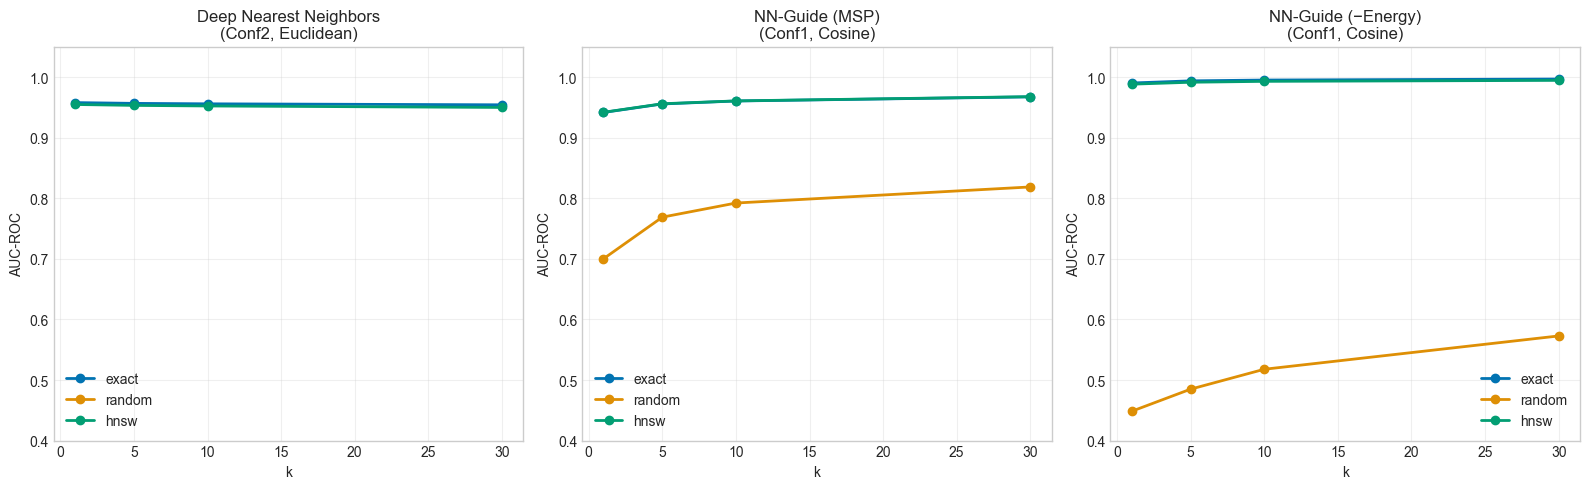

In [9]:
# ── OoD Visualization: AUC-ROC vs k ──────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# DNN: AUC-ROC vs k
ax = axes[0]
dnn_df = ood_results[ood_results['strategy'] == 'dnn']
for algo in dnn_df['algorithm'].unique():
    sub = dnn_df[dnn_df['algorithm'] == algo].groupby('k')['auroc'].mean()
    ax.plot(sub.index, sub.values, marker='o', label=algo, linewidth=2)
ax.set_title('Deep Nearest Neighbors\n(Conf2, Euclidean)')
ax.set_xlabel('k'); ax.set_ylabel('AUC-ROC')
ax.set_ylim(0.4, 1.05); ax.legend(); ax.grid(True, alpha=0.3)

# NN-Guide MSP
ax = axes[1]
nng_df = ood_results[ood_results['strategy'] == 'nn_guide_msp']
for algo in nng_df['algorithm'].unique():
    sub = nng_df[nng_df['algorithm'] == algo].groupby('k')['auroc'].mean()
    ax.plot(sub.index, sub.values, marker='o', label=algo, linewidth=2)
ax.set_title('NN-Guide (MSP)\n(Conf1, Cosine)')
ax.set_xlabel('k'); ax.set_ylabel('AUC-ROC')
ax.set_ylim(0.4, 1.05); ax.legend(); ax.grid(True, alpha=0.3)

# NN-Guide Energy
ax = axes[2]
nge_df = ood_results[ood_results['strategy'] == 'nn_guide_energy']
for algo in nge_df['algorithm'].unique():
    sub = nge_df[nge_df['algorithm'] == algo].groupby('k')['auroc'].mean()
    ax.plot(sub.index, sub.values, marker='o', label=algo, linewidth=2)
ax.set_title('NN-Guide (−Energy)\n(Conf1, Cosine)')
ax.set_xlabel('k'); ax.set_ylabel('AUC-ROC')
ax.set_ylim(0.4, 1.05); ax.legend(); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'ood_auroc_vs_k.png', dpi=150)
plt.show()

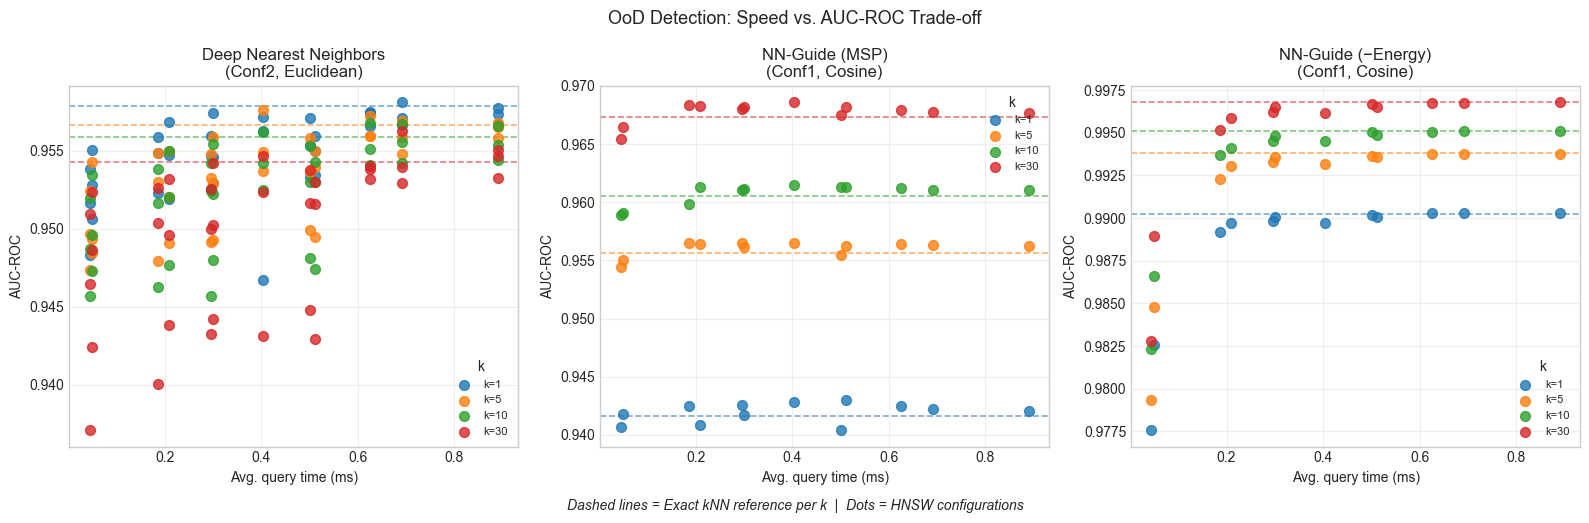

In [13]:
# ── OoD: Speed vs AUC-ROC trade-off (cleaner) ────────────────────────────────
import ast
import matplotlib.cm as cm

ood_df  = pd.read_csv(RESULTS_DIR / 'ood_results.csv')
img_df  = pd.read_csv(RESULTS_DIR / 'image_search_results.csv')

# Byg timing-opslag
timing_lookup = {}
for _, row in img_df.iterrows():
    try:
        p = ast.literal_eval(row['hyperparams'])
    except:
        p = {}
    key = (row['algorithm'], p.get('M', None), p.get('ef_search', None))
    timing_lookup[key] = row['avg_query_time'] * 1000

def get_query_time_ms(row):
    try:
        p = ast.literal_eval(row['hyperparams'])
    except:
        p = {}
    key = (row['algorithm'], p.get('M', None), p.get('ef_search', None))
    return timing_lookup.get(key, None)

ood_df['query_time_ms'] = ood_df.apply(get_query_time_ms, axis=1)

strategy_titles = {
    'dnn':             'Deep Nearest Neighbors\n(Conf2, Euclidean)',
    'nn_guide_msp':    'NN-Guide (MSP)\n(Conf1, Cosine)',
    'nn_guide_energy': 'NN-Guide (−Energy)\n(Conf1, Cosine)',
}

k_colors = {1: '#1f77b4', 5: '#ff7f0e', 10: '#2ca02c', 30: '#d62728'}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (strategy, title) in zip(axes, strategy_titles.items()):
    df = ood_df[ood_df['strategy'] == strategy]

    # Exact som vandret referencelinje per k
    exact_df = df[df['algorithm'] == 'exact']
    for k_val, grp in exact_df.groupby('k'):
        ax.axhline(grp['auroc'].mean(), color=k_colors[k_val],
                   linestyle='--', linewidth=1.2, alpha=0.6)

    # HNSW som scatter
    hnsw_df = df[(df['algorithm'] == 'hnsw') & (df['query_time_ms'].notna())]
    for k_val, grp in hnsw_df.groupby('k'):
        ax.scatter(grp['query_time_ms'], grp['auroc'],
                   color=k_colors[k_val], label=f'k={k_val}',
                   s=50, alpha=0.8, zorder=3)

    ax.set_title(title)
    ax.set_xlabel('Avg. query time (ms)')
    ax.set_ylabel('AUC-ROC')
    ax.legend(title='k', fontsize=8)
    ax.grid(True, alpha=0.3)

# Fælles forklaring
fig.text(0.5, -0.02,
         'Dashed lines = Exact kNN reference per k  |  Dots = HNSW configurations',
         ha='center', fontsize=10, style='italic')

plt.suptitle('OoD Detection: Speed vs. AUC-ROC Trade-off', fontsize=13)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'ood_speed_vs_auroc.png', dpi=150, bbox_inches='tight')
plt.show()


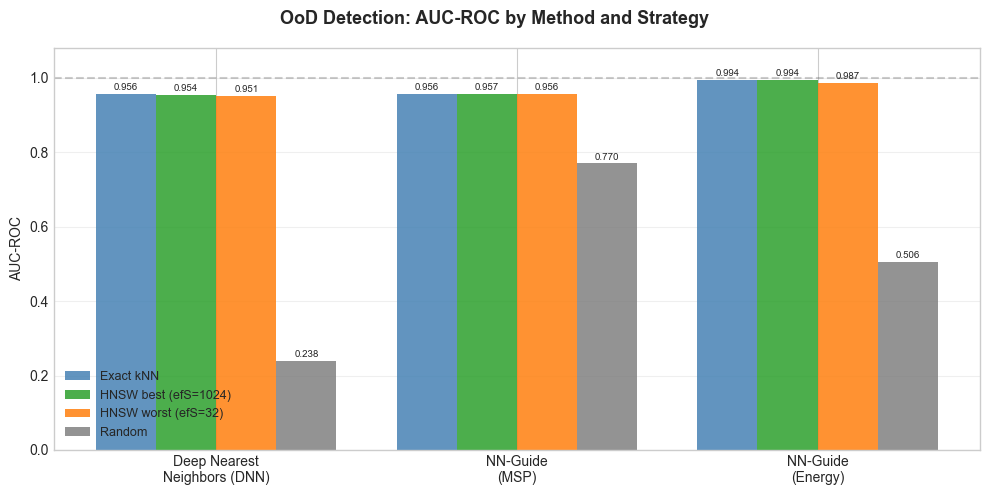

Saved: ood_auroc_vs_time.png


In [10]:
# ── 2.2 OoD Detection: AUC-ROC Comparison — Bar Chart ───────────────────────
import ast, numpy as np
import pandas as pd

ood_res = pd.read_csv(RESULTS_DIR / 'ood_results.csv')
ood_res['hp'] = ood_res['hyperparams'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) and x != '{}' else {})
ood_res['ef_search'] = ood_res['hp'].apply(lambda x: x.get('ef_search', None))

strategy_labels = {
    'dnn':             'Deep Nearest\nNeighbors (DNN)',
    'nn_guide_msp':    'NN-Guide\n(MSP)',
    'nn_guide_energy': 'NN-Guide\n(Energy)',
}
strategies = list(strategy_labels.keys())

# Global best/worst efSearch across all HNSW rows
hnsw_all = ood_res[ood_res['algorithm'] == 'hnsw']
best_ef  = hnsw_all['ef_search'].max()
worst_ef = hnsw_all['ef_search'].min()

# Build bar values per strategy
rows = []
for strat in strategies:
    sub = ood_res[ood_res['strategy'] == strat]
    exact_auc  = sub[sub['algorithm'] == 'exact']['auroc'].mean()
    random_auc = sub[sub['algorithm'] == 'random']['auroc'].mean()
    hnsw_sub   = sub[sub['algorithm'] == 'hnsw']
    best_hnsw  = hnsw_sub[hnsw_sub['ef_search'] == best_ef]['auroc'].mean() if len(hnsw_sub) > 0 else float('nan')
    worst_hnsw = hnsw_sub[hnsw_sub['ef_search'] == worst_ef]['auroc'].mean() if len(hnsw_sub) > 0 else float('nan')
    rows.append({'strategy': strat, 'exact': exact_auc, 'best_hnsw': best_hnsw,
                 'worst_hnsw': worst_hnsw, 'random': random_auc})

df_bar = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 5))
fig.suptitle('OoD Detection: AUC-ROC by Method and Strategy', fontsize=13, fontweight='bold')

x = np.arange(len(strategies))
width = 0.2
bars = [
    ('exact',      'steelblue', 'Exact kNN'),
    ('best_hnsw',  '#2ca02c',   f'HNSW best (efS={int(best_ef) if not np.isnan(best_ef) else "?"})',),
    ('worst_hnsw', '#ff7f0e',   f'HNSW worst (efS={int(worst_ef) if not np.isnan(worst_ef) else "?"})',),
    ('random',     'gray',      'Random'),
]

for i, (col, color, label) in enumerate(bars):
    offset = (i - 1.5) * width
    vals = df_bar[col].values
    rects = ax.bar(x + offset, vals, width, label=label, color=color, alpha=0.85)
    for rect, v in zip(rects, vals):
        if not np.isnan(v):
            ax.text(rect.get_x() + rect.get_width()/2, v + 0.005,
                    f'{v:.3f}', ha='center', va='bottom', fontsize=7)

ax.set_ylabel('AUC-ROC')
ax.set_ylim(0, 1.08)
ax.set_xticks(x)
ax.set_xticklabels([strategy_labels[s] for s in strategies])
ax.legend(fontsize=9)
ax.axhline(1.0, color='black', linestyle='--', alpha=0.2)
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'ood_auroc_vs_time.png', dpi=150)
plt.show()
print('Saved: ood_auroc_vs_time.png')


C:\Users\Emil\AppData\Local\Temp\ipykernel_11336\1499081417.py:34: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(list(deviations.values()), labels=list(deviations.keys()), patch_artist=True)


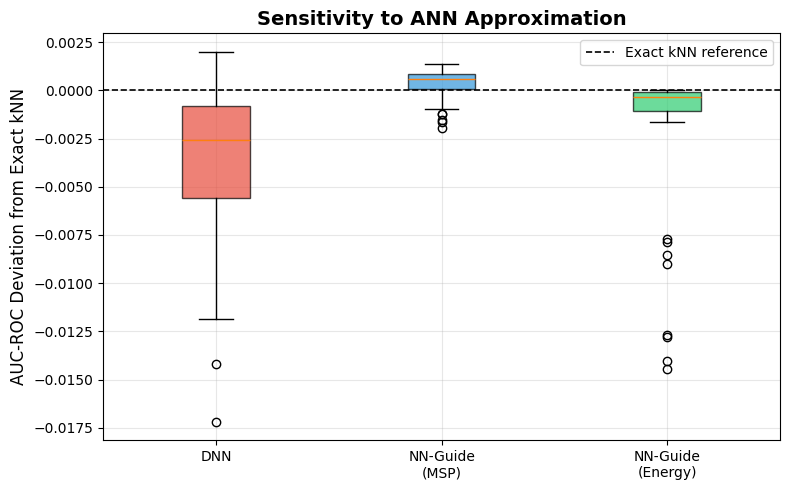

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

RESULTS_DIR = Path(r'C:\Users\Emil\Desktop\Emil Bachelor projekt\data\results')
ood_df = pd.read_csv(RESULTS_DIR / 'ood_results.csv')

strategy_labels = {
    'dnn':             'DNN',
    'nn_guide_msp':    'NN-Guide\n(MSP)',
    'nn_guide_energy': 'NN-Guide\n(Energy)',
}

deviations = {}

for strategy, label in strategy_labels.items():
    df = ood_df[ood_df['strategy'] == strategy]
    
    exact_ref = df[df['algorithm'] == 'exact'].groupby('k')['auroc'].mean()
    
    hnsw_df = df[df['algorithm'] == 'hnsw']
    devs = []
    for _, row in hnsw_df.iterrows():
        k = row['k']
        if k in exact_ref.index:
            devs.append(row['auroc'] - exact_ref[k])
    
    deviations[label] = devs

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#E74C3C', '#3498DB', '#2ECC71']

bp = ax.boxplot(list(deviations.values()), labels=list(deviations.keys()), patch_artist=True)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.axhline(0, color='black', linestyle='--', linewidth=1.2, label='Exact kNN reference')
ax.set_ylabel('AUC-ROC Deviation from Exact kNN', fontsize=12)
ax.set_title('Sensitivity to ANN Approximation', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'ood_boxplot_deviation.png', dpi=150, bbox_inches='tight')
plt.show()


## 2.2 Recall@k vs AUC-ROC Trade-off

Link search quality (Recall@k) to OoD performance (AUC-ROC).

In [11]:
# ── Summary table: Recall@k side by side with AUC-ROC ────────────────────────
print("=" * 70)
print("SUMMARY: AUC-ROC by algorithm and k")
print("=" * 70)

for strategy in ood_results['strategy'].unique():
    print(f"\n{strategy.upper()}")
    sub = ood_results[ood_results['strategy'] == strategy]
    pivot = sub.pivot_table(values='auroc', index='algorithm', columns='k').round(4)
    print(pivot.to_string())

print("\n(Values > 0.5 = better than random; 1.0 = perfect OoD detection)")

SUMMARY: AUC-ROC by algorithm and k

DNN
k              1       5       10      30
algorithm                                
exact      0.9579  0.9566  0.9559  0.9543
hnsw       0.9548  0.9533  0.9523  0.9499
random     0.2376  0.2381  0.2374  0.2390

NN_GUIDE_MSP
k              1       5       10      30
algorithm                                
exact      0.9416  0.9557  0.9606  0.9674
hnsw       0.9419  0.9560  0.9607  0.9677
random     0.7001  0.7688  0.7921  0.8187

NN_GUIDE_ENERGY
k              1       5       10      30
algorithm                                
exact      0.9903  0.9938  0.9951  0.9968
hnsw       0.9883  0.9915  0.9930  0.9946
random     0.4484  0.4849  0.5177  0.5727

(Values > 0.5 = better than random; 1.0 = perfect OoD detection)


---
# Final: Save All Results
---

In [23]:
# ── Print final summary ───────────────────────────────────────────────────────
print("Files saved in data/results/:")
for f in sorted(RESULTS_DIR.glob('*.csv')) + sorted(RESULTS_DIR.glob('*.png')):
    print(f"  {f.name}")

Files saved in data/results/:
  image_search_results.csv
  movielens_search_results.csv
  ood_results.csv
  recommender_results.csv
  hnsw_efsearch_recall.png
  image_recall_vs_k.png
  image_timing.png
  lsh_nbits_recall.png
  movielens_results.png
  ood_auroc_vs_k.png
  ood_auroc_vs_time.png
  recall_vs_auroc.png
  recall_vs_querytime.png
  recommender_results.png


---
# TASK 3 — Recommender Systems (Section 4.2)
---

## 3.1 Setup

**Item-Based kNN Recommendation** using MovieLens 10m.

| Step | Details |
|------|---------|
| Representation | Normalized movie vectors (10,677 × 69,878) — same as Task 1 |
| Similarity | Cosine (inner product on normalized vectors) |
| Train/Test split | Timestamp-based: hold out each user's **last** watched movie |
| Query | User's **second-to-last** movie (last in training) |
| Recommendation | Top-k most similar movies the user hasn't seen yet |
| Evaluation | **Hit Rate** = fraction of users where held-out movie is in top-k |

**Random baseline**: k random movies (not already watched) → expected hit rate ≈ k / 10,677

In [34]:
# ── Load ratings WITH timestamps for train/test split ─────────────────────────
print("Loading MovieLens ratings with timestamps...")
ratings_raw = pd.read_csv(
    RAW_DIR / 'ml-10M100K/ratings.dat',
    sep='::', engine='python',
    names=['user_id', 'item_id', 'rating', 'timestamp']
)
print(f"  Total ratings: {len(ratings_raw):,}")
print(f"  Users: {ratings_raw['user_id'].nunique():,}  Movies: {ratings_raw['item_id'].nunique():,}")

# ── Filter users with ≥ 5 ratings ─────────────────────────────────────────────
user_counts = ratings_raw.groupby('user_id').size()
active_users = user_counts[user_counts >= 5].index
ratings_f = ratings_raw[ratings_raw['user_id'].isin(active_users)].copy()
print(f"\nAfter filtering (≥5 ratings): {ratings_f['user_id'].nunique():,} users")

# ── Timestamp-based train/test split ──────────────────────────────────────────
# Sort by user + timestamp; last interaction per user → test set
ratings_sorted = ratings_f.sort_values(['user_id', 'timestamp'])

# Mark last row per user
last_mask = ratings_sorted.groupby('user_id').cumcount(ascending=False) == 0
test_ratings  = ratings_sorted[last_mask][['user_id', 'item_id']].copy()
train_ratings = ratings_sorted[~last_mask].copy()

print(f"\nTrain ratings: {len(train_ratings):,}")
print(f"Test  ratings: {len(test_ratings):,}  (1 per user = last watched movie)")

# ── Last training movie per user (= query for recommendation) ─────────────────
user_last_train = (
    train_ratings
    .sort_values('timestamp')
    .groupby('user_id')
    .last()
    .reset_index()[['user_id', 'item_id']]
    .rename(columns={'item_id': 'query_movie'})
)

# ── Build evaluation dataframe ─────────────────────────────────────────────────
rec_eval_df = user_last_train.merge(
    test_ratings.rename(columns={'item_id': 'target_movie'}),
    on='user_id', how='inner'
)

# Map movie IDs to matrix indices
movie_id_to_idx = {int(mid): i for i, mid in enumerate(ml_proc.movie_ids)}

# Only keep users where both query and target movies are in our index
rec_eval_df = rec_eval_df[
    rec_eval_df['query_movie'].isin(movie_id_to_idx) &
    rec_eval_df['target_movie'].isin(movie_id_to_idx)
].reset_index(drop=True)

# Map to matrix indices
rec_eval_df['query_idx']  = rec_eval_df['query_movie'].map(movie_id_to_idx)
rec_eval_df['target_idx'] = rec_eval_df['target_movie'].map(movie_id_to_idx)

# Build watched-movies set per user (training movies as matrix indices)
print("Building user watch history...")
user_watched_idx = (
    train_ratings[train_ratings['item_id'].isin(movie_id_to_idx)]
    .assign(item_idx=lambda df: df['item_id'].map(movie_id_to_idx))
    .groupby('user_id')['item_idx']
    .apply(set)
    .to_dict()
)

# ── Sample evaluation users ────────────────────────────────────────────────────
N_EVAL_USERS = int(len(rec_eval_df) * 0.5)
rng_rec = np.random.default_rng(42)
sample_idx = rng_rec.choice(len(rec_eval_df), size=min(N_EVAL_USERS, len(rec_eval_df)), replace=False)
rec_eval_sample = rec_eval_df.iloc[sample_idx].reset_index(drop=True)

print(f"\nEvaluation set: {len(rec_eval_sample):,} users")
print(f"  Avg watched movies per user: {np.mean([len(user_watched_idx.get(u, set())) for u in rec_eval_sample['user_id']]):.1f}")

Loading MovieLens ratings with timestamps...
  Total ratings: 10,000,054
  Users: 69,878  Movies: 10,677

After filtering (≥5 ratings): 69,878 users

Train ratings: 9,930,176
Test  ratings: 69,878  (1 per user = last watched movie)
Building user watch history...

Evaluation set: 34,939 users
  Avg watched movies per user: 141.8


In [35]:
## 3.2 Recommendation + Hit Rate Functions

def compute_hit_rate(faiss_index, eval_df, k, n_candidates=300):
    """
    Item-based kNN hit rate:
      - For each user: query = their last training movie
      - Search n_candidates similar movies from FAISS index
      - Filter out already-watched movies
      - Hit if target (held-out last movie) is in top-k
    """
    query_vecs = np.ascontiguousarray(
        ml_matrix[eval_df['query_idx'].values], dtype=np.float32
    )
    _, cand_indices = faiss_index.search(query_vecs, n_candidates)

    hits = 0
    for loc, (_, row) in enumerate(eval_df.iterrows()):
        user_id    = row['user_id']
        query_idx  = int(row['query_idx'])
        target_idx = int(row['target_idx'])
        watched    = user_watched_idx.get(user_id, set())

        recs = []
        for idx in cand_indices[loc]:
            idx = int(idx)
            if idx == query_idx or idx in watched:
                continue
            recs.append(idx)
            if len(recs) == k:
                break

        if target_idx in recs:
            hits += 1

    return hits / len(eval_df)


def random_hit_rate_theoretical(k, n_movies, avg_watched):
    """Theoretical random hit rate: k / (n_movies - avg_watched)."""
    return k / max(1, n_movies - avg_watched)


print('Recommendation functions defined.')
print(f'n_movies in index: {ml_matrix.shape[0]:,}')
print(f'n_candidates for filtering: 300 (handles up to ~270 watched movies)')


Recommendation functions defined.
n_movies in index: 10,677
n_candidates for filtering: 300 (handles up to ~270 watched movies)


In [36]:
## 3.3 Run Recommender Experiments

rec_rows = []
db = ml_matrix  # (10677, 69878) normalized float32

# Exact kNN
print('Building Exact index...')
exact_idx_rec, exact_bt_rec = build_exact_index(db, 'cosine')
for k in K_VALUES:
    print(f'  [Exact] k={k}...')
    t0 = time.perf_counter()
    hr = compute_hit_rate(exact_idx_rec, rec_eval_sample, k)
    qt = time.perf_counter() - t0
    rec_rows.append({
        'algorithm': 'exact', 'k': k, 'hyperparams': '{}',
        'hit_rate': hr, 'index_build_time': exact_bt_rec,
        'query_time': qt,
        'amortized_time': amortized_time(exact_bt_rec, qt, len(rec_eval_sample))
    })
    print(f'    Hit Rate@{k} = {hr:.4f}')

# Random baseline (theoretical)
avg_watched = np.mean([len(user_watched_idx.get(u, set())) for u in rec_eval_sample['user_id']])
for k in K_VALUES:
    rnd_hr = random_hit_rate_theoretical(k, ml_matrix.shape[0], avg_watched)
    rec_rows.append({
        'algorithm': 'random', 'k': k, 'hyperparams': '{}',
        'hit_rate': rnd_hr, 'index_build_time': 0.0,
        'query_time': 0.0, 'amortized_time': 0.0
    })
print(f'Random baseline Hit Rate@10 = {random_hit_rate_theoretical(10, ml_matrix.shape[0], avg_watched):.6f}')

# HNSW
hp = HYPERPARAM_RANGES['movies']['hnsw']
for M in hp['M']:
    for ef_c in hp['ef_construction']:
        print(f'\nBuilding HNSW M={M}, efC={ef_c}...')
        idx_hnsw, bt_hnsw = build_hnsw_index(db, 'cosine', M, ef_c, ef_search=hp['ef_search'][0])
        for ef_s in hp['ef_search']:
            idx_hnsw.hnsw.efSearch = ef_s
            for k in K_VALUES:
                t0 = time.perf_counter()
                hr = compute_hit_rate(idx_hnsw, rec_eval_sample, k)
                qt = time.perf_counter() - t0
                rec_rows.append({
                    'algorithm': 'hnsw', 'k': k,
                    'hyperparams': str({'M': M, 'ef_construction': ef_c, 'ef_search': ef_s}),
                    'hit_rate': hr, 'index_build_time': bt_hnsw,
                    'query_time': qt,
                    'amortized_time': amortized_time(bt_hnsw, qt, len(rec_eval_sample))
                })
            last_k10 = [r for r in rec_rows if r['algorithm'] == 'hnsw' and r['k'] == 10][-1]
            print(f'  efS={ef_s} | Hit@10={last_k10["hit_rate"]:.4f}')

# LSH
for nbits in HYPERPARAM_RANGES['movies']['lsh']['nbits']:
    print(f'\nBuilding LSH nbits={nbits}...')
    idx_lsh, bt_lsh = build_lsh_index(db, nbits)
    for k in K_VALUES:
        t0 = time.perf_counter()
        hr = compute_hit_rate(idx_lsh, rec_eval_sample, k)
        qt = time.perf_counter() - t0
        rec_rows.append({
            'algorithm': 'lsh', 'k': k,
            'hyperparams': str({'nbits': nbits}),
            'hit_rate': hr, 'index_build_time': bt_lsh,
            'query_time': qt,
            'amortized_time': amortized_time(bt_lsh, qt, len(rec_eval_sample))
        })
    last_k10 = [r for r in rec_rows if r['algorithm'] == 'lsh' and r['k'] == 10][-1]
    print(f'  Hit@10={last_k10["hit_rate"]:.4f}')

# Save
rec_results = pd.DataFrame(rec_rows)
rec_results.to_csv(RESULTS_DIR / 'recommender_results.csv', index=False)
print(f'\nSaved {len(rec_results)} recommender result rows')
print(rec_results[rec_results['k'] == 10].groupby('algorithm')['hit_rate'].mean().round(4))


Building Exact index...
  [Exact] k=1...
    Hit Rate@1 = 0.0315
  [Exact] k=5...
    Hit Rate@5 = 0.0853
  [Exact] k=10...
    Hit Rate@10 = 0.1240
  [Exact] k=30...
    Hit Rate@30 = 0.2264
Random baseline Hit Rate@10 = 0.000949

Building HNSW M=8, efC=8...
  efS=4 | Hit@10=0.1135
  efS=8 | Hit@10=0.1181
  efS=16 | Hit@10=0.1219
  efS=32 | Hit@10=0.1230
  efS=64 | Hit@10=0.1233

Building HNSW M=8, efC=16...
  efS=4 | Hit@10=0.1110
  efS=8 | Hit@10=0.1181
  efS=16 | Hit@10=0.1210
  efS=32 | Hit@10=0.1234
  efS=64 | Hit@10=0.1233

Building HNSW M=8, efC=32...
  efS=4 | Hit@10=0.1138
  efS=8 | Hit@10=0.1206
  efS=16 | Hit@10=0.1232
  efS=32 | Hit@10=0.1235
  efS=64 | Hit@10=0.1236

Building HNSW M=16, efC=8...
  efS=4 | Hit@10=0.1177
  efS=8 | Hit@10=0.1215
  efS=16 | Hit@10=0.1225
  efS=32 | Hit@10=0.1228
  efS=64 | Hit@10=0.1229

Building HNSW M=16, efC=16...
  efS=4 | Hit@10=0.1208
  efS=8 | Hit@10=0.1222
  efS=16 | Hit@10=0.1236
  efS=32 | Hit@10=0.1237
  efS=64 | Hit@10=0.1237

Bui

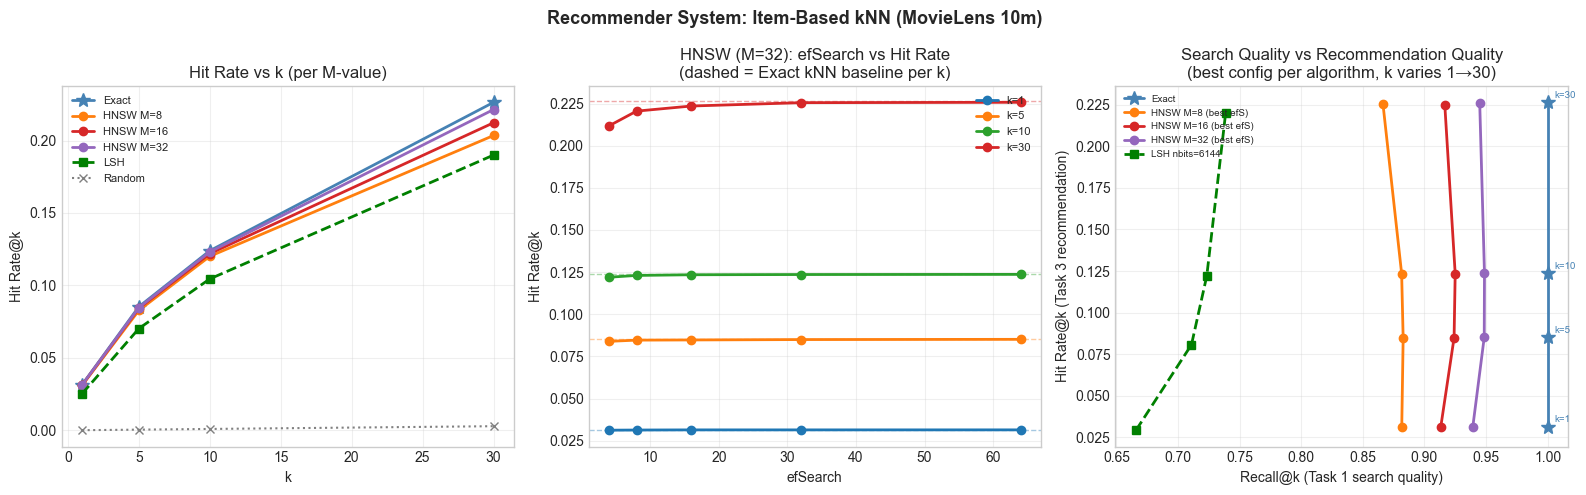

Saved: recommender_results.png


In [37]:
## 3.4 Recommender System Visualizations

import ast
rec_res = pd.read_csv(RESULTS_DIR / 'recommender_results.csv')
ml_res  = pd.read_csv(RESULTS_DIR / 'movielens_search_results.csv')

for df in [rec_res, ml_res]:
    df['hp'] = df['hyperparams'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) and x != '{}' else {})
    df['ef_search'] = df['hp'].apply(lambda x: x.get('ef_search', None))
    df['nbits_v']   = df['hp'].apply(lambda x: x.get('nbits', None))
    df['M_val']     = df['hp'].apply(lambda x: x.get('M', None))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Recommender System: Item-Based kNN (MovieLens 10m)', fontsize=13, fontweight='bold')

# ── Plot 1: Hit Rate vs k — per-M curves for HNSW ───────────────────────────
ax = axes[0]
# Exact
sub = rec_res[rec_res['algorithm'] == 'exact'].groupby('k')['hit_rate'].mean().reset_index()
ax.plot(sub['k'], sub['hit_rate'], marker='*', color='steelblue', label='Exact', linewidth=2, markersize=10)

# HNSW — one curve per M (averaged over efC/efS)
colors_h = ['#ff7f0e', '#d62728', '#9467bd']
hnsw_r = rec_res[rec_res['algorithm'] == 'hnsw']
for idx, M_val in enumerate(sorted(hnsw_r['M_val'].dropna().unique())):
    sub = hnsw_r[hnsw_r['M_val'] == M_val].groupby('k')['hit_rate'].mean().reset_index()
    ax.plot(sub['k'], sub['hit_rate'], marker='o', color=colors_h[idx % 3],
            label=f'HNSW M={int(M_val)}', linewidth=2)

# LSH
sub = rec_res[rec_res['algorithm'] == 'lsh'].groupby('k')['hit_rate'].mean().reset_index()
ax.plot(sub['k'], sub['hit_rate'], marker='s', color='green', label='LSH', linewidth=2, linestyle='--')

# Random
sub = rec_res[rec_res['algorithm'] == 'random'].groupby('k')['hit_rate'].mean().reset_index()
ax.plot(sub['k'], sub['hit_rate'], marker='x', color='gray', label='Random', linewidth=1.5, linestyle=':')

ax.set_xlabel('k'); ax.set_ylabel('Hit Rate@k')
ax.set_title('Hit Rate vs k (per M-value)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# ── Plot 2: HNSW efSearch effect — multiple k values ────────────────────────
ax = axes[1]
hnsw_sub = rec_res[rec_res['algorithm'] == 'hnsw'].copy()
# Use best M (M=32) to keep it clean
best_M = hnsw_sub['M_val'].max()
hnsw_bestM = hnsw_sub[hnsw_sub['M_val'] == best_M]

k_colors = {1: '#1f77b4', 5: '#ff7f0e', 10: '#2ca02c', 30: '#d62728'}
for k_val in sorted(rec_res['k'].unique()):
    m_sub = (hnsw_bestM[hnsw_bestM['k'] == k_val]
             .groupby('ef_search')['hit_rate'].mean().reset_index()
             .sort_values('ef_search'))
    ax.plot(m_sub['ef_search'], m_sub['hit_rate'], marker='o',
            color=k_colors.get(k_val, 'black'), label=f'k={k_val}', linewidth=2)
    # Add exact kNN baseline as horizontal marker
    exact_hr = rec_res[(rec_res['algorithm'] == 'exact') & (rec_res['k'] == k_val)]['hit_rate'].mean()
    ax.axhline(exact_hr, color=k_colors.get(k_val, 'black'), linestyle='--', alpha=0.4, linewidth=1)

ax.set_xlabel('efSearch'); ax.set_ylabel('Hit Rate@k')
ax.set_title(f'HNSW (M={int(best_M)}): efSearch vs Hit Rate\n(dashed = Exact kNN baseline per k)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# ── Plot 3: Search Quality vs Recommendation Quality — curves varying k ──────
# For each algorithm (best config), plot Recall@k vs Hit Rate@k as k varies 1→30
ax = axes[2]
ml_base = ml_res[ml_res['n_queries'] == 1000]

# Exact: recall=1 at all k, so just plot hit rate vs k
exact_rec = ml_base[ml_base['algorithm'] == 'exact'].groupby('k')['recall'].mean().reset_index()
exact_hr  = rec_res[rec_res['algorithm'] == 'exact'].groupby('k')['hit_rate'].mean().reset_index()
merged_e  = exact_rec.merge(exact_hr, on='k')
ax.plot(merged_e['recall'], merged_e['hit_rate'], marker='*', color='steelblue',
        label='Exact', linewidth=2, markersize=10)
for _, row in merged_e.iterrows():
    ax.annotate(f'k={int(row["k"])}', (row['recall'], row['hit_rate']),
                textcoords='offset points', xytext=(5, 3), fontsize=7, color='steelblue')

# HNSW — best config (max M, max efSearch) for each k
hnsw_ml = ml_base[ml_base['algorithm'] == 'hnsw']
hnsw_rc = rec_res[rec_res['algorithm'] == 'hnsw']
for idx, M_val in enumerate(sorted(hnsw_ml['M_val'].dropna().unique())):
    # Use highest efSearch per k
    best_ef = hnsw_ml['ef_search'].max()
    r_sub = (hnsw_ml[(hnsw_ml['M_val'] == M_val) & (hnsw_ml['ef_search'] == best_ef)]
             .groupby('k')['recall'].mean().reset_index())
    h_sub = (hnsw_rc[(hnsw_rc['M_val'] == M_val) & (hnsw_rc['ef_search'] == best_ef)]
             .groupby('k')['hit_rate'].mean().reset_index())
    merged = r_sub.merge(h_sub, on='k').sort_values('k')
    if len(merged) > 0:
        ax.plot(merged['recall'], merged['hit_rate'], marker='o',
                color=colors_h[idx % 3], label=f'HNSW M={int(M_val)} (best efS)', linewidth=2)

# LSH — best nbits
lsh_ml = ml_base[ml_base['algorithm'] == 'lsh']
lsh_rc = rec_res[rec_res['algorithm'] == 'lsh']
best_nb = lsh_ml['nbits_v'].max()
r_lsh = lsh_ml[lsh_ml['nbits_v'] == best_nb].groupby('k')['recall'].mean().reset_index()
h_lsh = lsh_rc[lsh_rc['nbits_v'] == best_nb].groupby('k')['hit_rate'].mean().reset_index()
merged_lsh = r_lsh.merge(h_lsh, on='k').sort_values('k')
if len(merged_lsh) > 0:
    ax.plot(merged_lsh['recall'], merged_lsh['hit_rate'], marker='s',
            color='green', linestyle='--', label=f'LSH nbits={int(best_nb)}', linewidth=2)

ax.set_xlabel('Recall@k (Task 1 search quality)')
ax.set_ylabel('Hit Rate@k (Task 3 recommendation)')
ax.set_title('Search Quality vs Recommendation Quality\n(best config per algorithm, k varies 1→30)')
ax.legend(fontsize=7); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'recommender_results.png', dpi=150)
plt.show()
print('Saved: recommender_results.png')


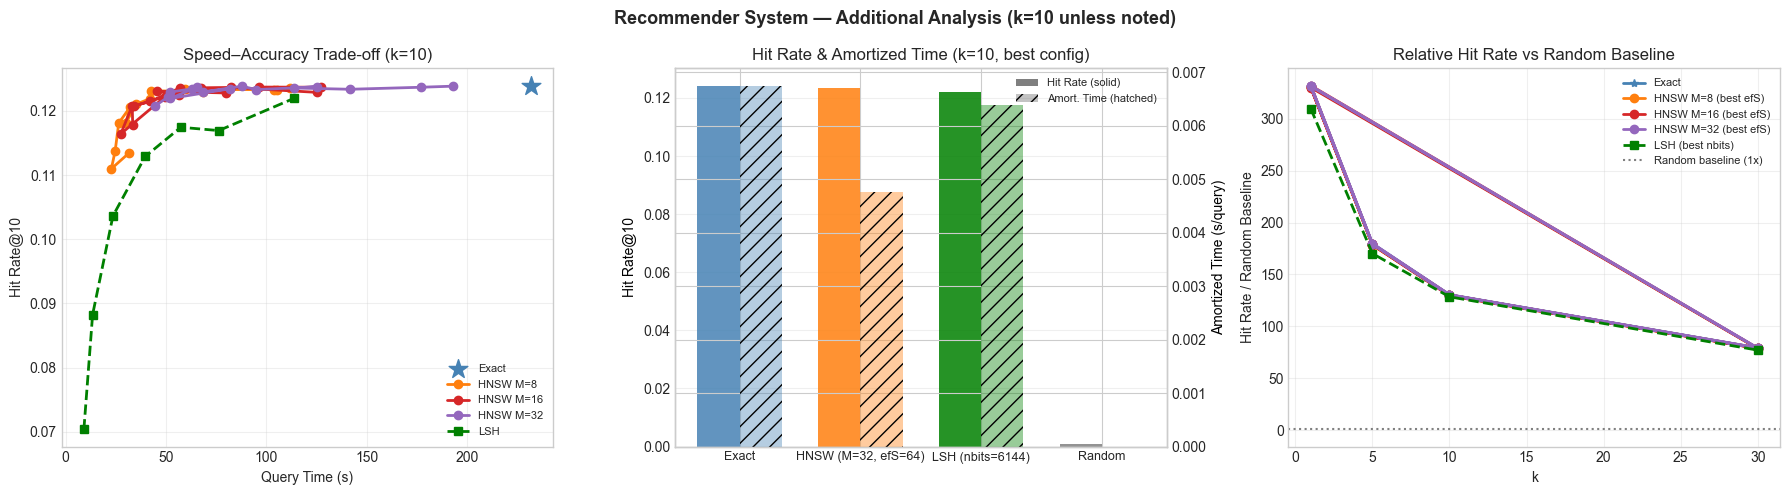

Saved: recommender_extra.png


In [38]:
# ── Extra Recommender Visualizations ─────────────────────────────────────────
import ast, numpy as np
rec_res = pd.read_csv(RESULTS_DIR / "recommender_results.csv")
rec_res["hp"]       = rec_res["hyperparams"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) and x != "{}" else {})
rec_res["M_val"]    = rec_res["hp"].apply(lambda x: x.get("M", None))
rec_res["ef_search"]= rec_res["hp"].apply(lambda x: x.get("ef_search", None))
rec_res["nbits_v"]  = rec_res["hp"].apply(lambda x: x.get("nbits", None))

colors_h = ["#ff7f0e", "#d62728", "#9467bd"]
k_fixed  = 10  # reference k for plots 1 & 2

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Recommender System — Additional Analysis (k=10 unless noted)",
             fontsize=13, fontweight="bold")

# ── Plot 1: Hit Rate vs Query Time ───────────────────────────────────────────
ax = axes[0]

# Exact
e = rec_res[(rec_res["algorithm"] == "exact") & (rec_res["k"] == k_fixed)]
ax.scatter(e["query_time"], e["hit_rate"], marker="*", s=200, color="steelblue", label="Exact", zorder=5)

# HNSW — one point per (M, ef_search) config
hnsw = rec_res[(rec_res["algorithm"] == "hnsw") & (rec_res["k"] == k_fixed)]
for idx, M_val in enumerate(sorted(hnsw["M_val"].dropna().unique())):
    sub = hnsw[hnsw["M_val"] == M_val].sort_values("ef_search")
    ax.plot(sub["query_time"], sub["hit_rate"], marker="o",
            color=colors_h[idx % 3], label=f"HNSW M={int(M_val)}", linewidth=2)

# LSH
lsh = rec_res[(rec_res["algorithm"] == "lsh") & (rec_res["k"] == k_fixed)].sort_values("nbits_v")
ax.plot(lsh["query_time"], lsh["hit_rate"], marker="s", color="green",
        linestyle="--", label="LSH", linewidth=2)

ax.set_xlabel("Query Time (s)")
ax.set_ylabel(f"Hit Rate@{k_fixed}")
ax.set_title(f"Speed–Accuracy Trade-off (k={k_fixed})")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# ── Plot 2: Bar Chart — Amortized Time & Hit Rate per algorithm (best config) ─
ax = axes[1]

def best_config(df, algo, k):
    sub = df[(df["algorithm"] == algo) & (df["k"] == k)]
    if algo == "hnsw":
        sub = sub[(sub["M_val"] == sub["M_val"].max()) & (sub["ef_search"] == sub["ef_search"].max())]
    elif algo == "lsh":
        sub = sub[sub["nbits_v"] == sub["nbits_v"].max()]
    return sub.iloc[0] if len(sub) > 0 else None

algos      = ["exact", "hnsw", "lsh", "random"]
algo_labels= ["Exact", "HNSW (M=32, efS=64)", "LSH (nbits=6144)", "Random"]
bar_colors = ["steelblue", "#ff7f0e", "green", "gray"]

hit_rates   = [best_config(rec_res, a, k_fixed)["hit_rate"]       for a in algos]
amort_times = [best_config(rec_res, a, k_fixed)["amortized_time"]  for a in algos]

x = np.arange(len(algos))
width = 0.35

ax2_twin = ax.twinx()
bars1 = ax.bar(x - width/2, hit_rates,   width, color=bar_colors, alpha=0.85, label="Hit Rate")
bars2 = ax2_twin.bar(x + width/2, amort_times, width, color=bar_colors, alpha=0.4,
                     hatch="//", label="Amortized Time")

ax.set_xticks(x); ax.set_xticklabels(algo_labels, fontsize=9)
ax.set_ylabel(f"Hit Rate@{k_fixed}", color="black")
ax2_twin.set_ylabel("Amortized Time (s/query)", color="black")
ax.set_title(f"Hit Rate & Amortized Time (k={k_fixed}, best config)")

from matplotlib.patches import Patch
legend_els = [Patch(facecolor="dimgray", alpha=0.85, label="Hit Rate (solid)"),
              Patch(facecolor="dimgray", alpha=0.4,  hatch="//", label="Amort. Time (hatched)")]
ax.legend(handles=legend_els, fontsize=8, loc="upper right")
ax.grid(True, alpha=0.3, axis="y")

# ── Plot 4: Relative Hit Rate vs Random Baseline ─────────────────────────────
ax = axes[2]

rand = rec_res[rec_res["algorithm"] == "random"][["k","hit_rate"]].rename(columns={"hit_rate":"rand_hr"})

def plot_relative(df, algo, label, color, marker, linestyle="-"):
    if algo == "hnsw":
        best_M  = df[df["algorithm"]=="hnsw"]["M_val"].max()
        best_ef = df[df["algorithm"]=="hnsw"]["ef_search"].max()
        sub = df[(df["algorithm"]=="hnsw") & (df["M_val"]==best_M) & (df["ef_search"]==best_ef)]
    elif algo == "lsh":
        best_nb = df[df["algorithm"]=="lsh"]["nbits_v"].max()
        sub = df[(df["algorithm"]=="lsh") & (df["nbits_v"]==best_nb)]
    else:
        sub = df[df["algorithm"]==algo]
    merged = sub.merge(rand, on="k")
    merged["relative_hr"] = merged["hit_rate"] / merged["rand_hr"]
    ax.plot(merged["k"], merged["relative_hr"], marker=marker, color=color,
            label=label, linewidth=2, linestyle=linestyle)

plot_relative(rec_res, "exact", "Exact",         "steelblue", "*")
for idx, M_val in enumerate(sorted(rec_res[rec_res["algorithm"]=="hnsw"]["M_val"].dropna().unique())):
    best_ef = rec_res[rec_res["algorithm"]=="hnsw"]["ef_search"].max()
    sub = rec_res[(rec_res["algorithm"]=="hnsw") & (rec_res["M_val"]==M_val) & (rec_res["ef_search"]==best_ef)]
    merged = sub.merge(rand, on="k")
    merged["relative_hr"] = merged["hit_rate"] / merged["rand_hr"]
    ax.plot(merged["k"], merged["relative_hr"], marker="o", color=colors_h[idx % 3],
            label=f"HNSW M={int(M_val)} (best efS)", linewidth=2)
plot_relative(rec_res, "lsh", "LSH (best nbits)", "green", "s", "--")

ax.axhline(1, color="gray", linestyle=":", linewidth=1.5, label="Random baseline (1x)")
ax.set_xlabel("k")
ax.set_ylabel("Hit Rate / Random Baseline")
ax.set_title("Relative Hit Rate vs Random Baseline")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "recommender_extra.png", dpi=150)
plt.show()
print("Saved: recommender_extra.png")


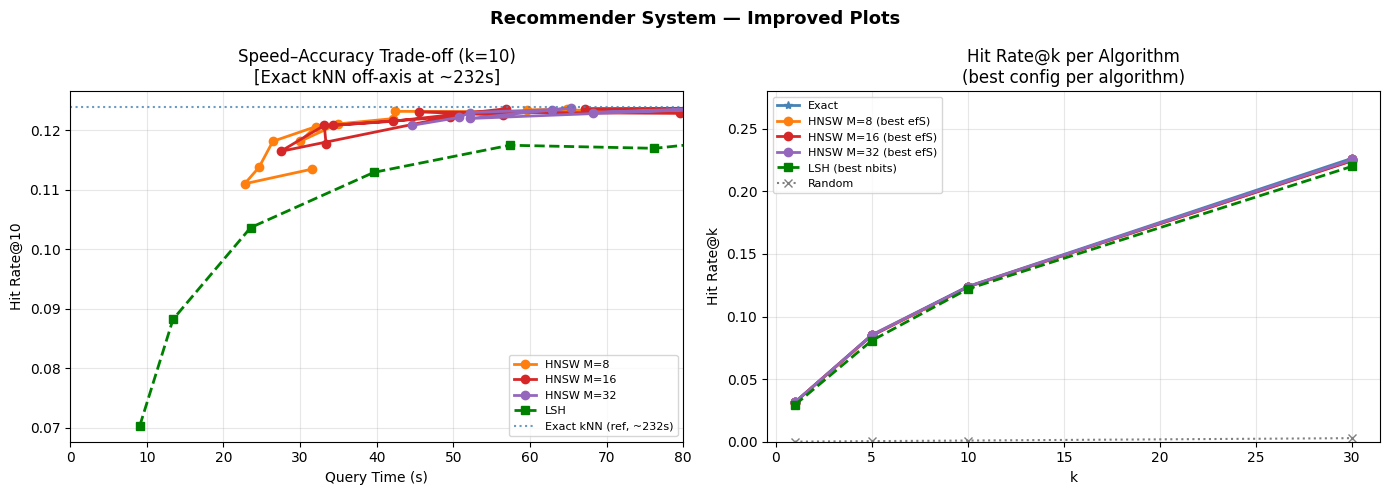

In [25]:
# ── Recommender: Improved Plots ───────────────────────────────────────────────
import ast, numpy as np

rec_res = pd.read_csv(RESULTS_DIR / "recommender_results.csv")
rec_res["hp"]        = rec_res["hyperparams"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) and x != "{}" else {})
rec_res["M_val"]     = rec_res["hp"].apply(lambda x: x.get("M", None))
rec_res["ef_search"] = rec_res["hp"].apply(lambda x: x.get("ef_search", None))
rec_res["nbits_v"]   = rec_res["hp"].apply(lambda x: x.get("nbits", None))

colors_h = ["#ff7f0e", "#d62728", "#9467bd"]
k_fixed  = 10

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Recommender System — Improved Plots", fontsize=13, fontweight="bold")

# ── Plot 1: Speed-Accuracy zoomed ────────────────────────────────────────────
ax = axes[0]

exact_row = rec_res[(rec_res["algorithm"] == "exact") & (rec_res["k"] == k_fixed)].iloc[0]

hnsw = rec_res[(rec_res["algorithm"] == "hnsw") & (rec_res["k"] == k_fixed)]
for idx, M_val in enumerate(sorted(hnsw["M_val"].dropna().unique())):
    sub = hnsw[hnsw["M_val"] == M_val].sort_values("ef_search")
    ax.plot(sub["query_time"], sub["hit_rate"], marker="o",
            color=colors_h[idx % 3], label=f"HNSW M={int(M_val)}", linewidth=2)

lsh = rec_res[(rec_res["algorithm"] == "lsh") & (rec_res["k"] == k_fixed)].sort_values("nbits_v")
ax.plot(lsh["query_time"], lsh["hit_rate"], marker="s", color="green",
        linestyle="--", label="LSH", linewidth=2)

ax.axhline(exact_row["hit_rate"], color="steelblue", linestyle=":", linewidth=1.5, alpha=0.8,
           label=f"Exact kNN (ref, ~{exact_row['query_time']:.0f}s)")

ax.set_xlim(0, 80)
ax.set_xlabel("Query Time (s)")
ax.set_ylabel(f"Hit Rate@{k_fixed}")
ax.set_title(f"Speed–Accuracy Trade-off (k={k_fixed})\n[Exact kNN off-axis at ~{exact_row['query_time']:.0f}s]")
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

# ── Plot 2: Absolute Hit Rate@k zoomed ───────────────────────────────────────
ax = axes[1]

def get_best(df, algo):
    if algo == "hnsw":
        best_M  = df[df["algorithm"]=="hnsw"]["M_val"].max()
        best_ef = df[df["algorithm"]=="hnsw"]["ef_search"].max()
        return df[(df["algorithm"]=="hnsw") & (df["M_val"]==best_M) & (df["ef_search"]==best_ef)]
    elif algo == "lsh":
        best_nb = df[df["algorithm"]=="lsh"]["nbits_v"].max()
        return df[(df["algorithm"]=="lsh") & (df["nbits_v"]==best_nb)]
    else:
        return df[df["algorithm"]==algo]

# Exact
sub = get_best(rec_res, "exact").sort_values("k")
ax.plot(sub["k"], sub["hit_rate"], marker="*", color="steelblue",
        label="Exact", linewidth=2)

# HNSW per M
for idx, M_val in enumerate(sorted(rec_res[rec_res["algorithm"]=="hnsw"]["M_val"].dropna().unique())):
    best_ef = rec_res[rec_res["algorithm"]=="hnsw"]["ef_search"].max()
    sub = rec_res[(rec_res["algorithm"]=="hnsw") & (rec_res["M_val"]==M_val) & (rec_res["ef_search"]==best_ef)].sort_values("k")
    ax.plot(sub["k"], sub["hit_rate"], marker="o", color=colors_h[idx % 3],
            label=f"HNSW M={int(M_val)} (best efS)", linewidth=2)

# LSH
sub = get_best(rec_res, "lsh").sort_values("k")
ax.plot(sub["k"], sub["hit_rate"], marker="s", color="green",
        linestyle="--", label="LSH (best nbits)", linewidth=2)

# Random
sub = get_best(rec_res, "random").sort_values("k")
ax.plot(sub["k"], sub["hit_rate"], marker="x", color="gray",
        linestyle=":", label="Random", linewidth=1.5)

ax.set_xlabel("k")
ax.set_ylabel("Hit Rate@k")
ax.set_title("Hit Rate@k per Algorithm\n(best config per algorithm)")
ax.set_ylim(0, 0.28)
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "recommender_improved.png", dpi=150, bbox_inches="tight")
plt.show()
